# 반도체 웨이퍼 결함 데이터로 배우는 머신러닝 A to Z
### 바이브코딩(Vibe Coding) 실습판 — 회귀 · 분류 · 평가지표 · 변수 중요도

| 항목 | 내용 |
|---|---|
| **과정** | 스마트제조 데이터의 이해 — 머신러닝 편 |
| **데이터** | `반도체_웨이퍼_basic_raw_data.csv` (63,908행 × 25열, 결함 1개 = 1행) |
| **선수 학습** | `반도체_웨이퍼_EDA_기초통계_A_to_Z.ipynb` (EDA는 앞 노트북에서 완료) |
| **도구** | Python · pandas · scikit-learn · matplotlib · seaborn + **생성형 AI** |
| **분류 과제** | 검사 장비가 잡은 결함이 **진성결함(REAL)인지 가성결함(FALSE)인지** 판정 |
| **회귀 과제** | 크기 측정값 없이 **광학 신호만으로 결함 크기(SIZE_D, µm)를 추정** |

---

## 목차

| 장 | 주제 | 핵심 키워드 |
|:---:|---|---|
| **가이드** | 바이브코딩 가이드 (ML 편) | ML 프롬프트 구조, 세션 시작 프롬프트 |
| **0** | 실습 환경 준비 | scikit-learn, 공통 설정 |
| **1** | 머신러닝 개념 | 지도학습, 회귀 vs 분류, 과적합, 데이터 누수 |
| **2** | 문제 정의 & 데이터 준비 | 타깃·특성 선정, 누수 변수 제거 |
| **3** | 데이터 분할 & 전처리 파이프라인 | 학습/테스트, 교차검증, 그룹 분할, Pipeline |
| **4** | 평가지표 선택 | 혼동행렬, 정밀도·재현율·F1·AUC, MAE·RMSE·R² |
| **5** | 분류 모델링 | 기준 모델 → 로지스틱 → 트리 → 앙상블, 튜닝, 임계값 |
| **6** | 회귀 모델링 | 로그 변환 타깃, 모델 비교, 잔차 분석 |
| **7** | 변수 중요도 | 계수, 불순도 중요도, 순열 중요도, 그룹 중요도, PDP |
| **8** | 모델 저장 · 종합 리포트 · 연습문제 | 프롬프트 작성 실습 |

```
 문제 정의 → 데이터 준비 → 분할 → 전처리 → 기준 모델 → 모델 비교(교차검증) → 튜닝
     → 테스트 평가 → 임계값/오차 분석 → 변수 중요도 → 저장·보고
```

---
# 바이브코딩 가이드 — 머신러닝 편

이 노트북의 **모든 코드 셀 위에는 `프롬프트 Pxx`** 가 있습니다.

```
 ① 프롬프트 읽기  →  ② AI에게 복사·붙여넣기  →  ③ 생성된 코드 실행
        ▲                                              │
        │                                              ▼
 ⑥ 프롬프트 수정  ◀──  ⑤ 차이점 분석  ◀──  ④ 노트북의 '예시 코드'와 비교
```

## 머신러닝 프롬프트의 5요소 — 맥락 · 작업 · **검증 방법** · 조건 · 출력
EDA 프롬프트(맥락·작업·조건·출력)에 **검증 방법**이 하나 더 붙습니다. 머신러닝은 "어떻게 평가하느냐"를 빼면 AI가 **누수가 있는 코드**를 만들기 쉽기 때문입니다.

| 요소 | 설명 | 예시 |
|---|---|---|
| **맥락** | 변수 이름·현재 상태 | "`Xc_tr`, `yc_tr`에 학습용 분류 데이터가 있어. 1=REAL이야." |
| **작업** | 무엇을 할지 | "로지스틱 회귀와 랜덤포레스트를 비교해줘." |
| **검증 방법** | 분할·교차검증·지표 | "`GroupKFold(5)`로 `g_tr`(로트) 기준 교차검증, 지표는 ROC-AUC." |
| **조건** | 라이브러리·제약 | "scikit-learn `Pipeline`으로 전처리를 포함하고 `random_state=42`." |
| **출력** | 결과 형태 | "모델별 평균±표준편차 표, 소수점 3자리, 한글 주석." |

> **나쁜 예** : "랜덤포레스트로 분류해줘"
> **좋은 예** : "`Xc_tr`/`yc_tr`로 랜덤포레스트 분류기를 `Pipeline`(전처리 `make_prep`)으로 만들고, `g_tr` 기준 `GroupKFold(5)` 교차검증으로 ROC-AUC 평균과 표준편차를 출력해줘. 테스트 데이터는 쓰지 마."

## AI가 만든 머신러닝 코드 검증 체크리스트
- [ ] **테스트 데이터를 학습·튜닝·임계값 결정에 쓰지 않았는가?** (가장 흔한 실수)
- [ ] **스케일러·인코더를 전체 데이터로 `fit` 하지 않았는가?** → `Pipeline` 안에 넣었는지 확인
- [ ] **타깃을 그대로 담은 변수(누수 변수)가 특성에 들어가지 않았는가?** (예: `Class`)
- [ ] **같은 로트가 학습·테스트에 동시에 들어가지 않았는가?** (그룹 분할)
- [ ] **기준 모델(Dummy)보다 얼마나 좋은지 비교했는가?**
- [ ] **지표가 문제의 목적과 맞는가?** (정확도만 보고 있지 않은가?)
- [ ] **`random_state`를 고정해 결과가 재현되는가?**

## 세션 시작 프롬프트 (가장 먼저 AI에게 입력하세요)
```text
너는 제조 데이터 머신러닝을 가르치는 Python 튜터야.
Jupyter Notebook에서 pandas, numpy, scikit-learn, matplotlib, seaborn으로 실습할 거야.
EDA는 이미 끝났고, 이번에는 모델링에 집중해.

[데이터] 반도체_웨이퍼_basic_raw_data.csv (UTF-8 BOM, 63,908행 × 25열, 결함 1개 = 1행)
- 식별: Step, Step_desc(공정: PC, RMG, CBCMP), Lot Name(로트), Slot No, Defect No
- 분류 결과: Class(결함 분류 코드, 9=가성결함), IS_DEFECT('REAL'/'FALSE')
- 크기: SIZE_X, SIZE_Y, SIZE_D(µm), DEFECT_AREA(µm²)
- 신호: INTENSITY, POLARITY(-1/0/1), ENERGY_PARAM, MDAT_OFFSET, MDAT_GL, MDAT_NOISE,
        RELATIVEMAGNITUDE, PATCHDEFECTSIGNAL
- 형상: ALIGNRATIO, SPOTLIKENESS, PATCHNOISE, ACTIVERATIO
- 위치: RADIUS(µm), ANGLE(도)

[과제]
- 분류: IS_DEFECT 예측 (REAL=1, FALSE=0). Class는 타깃을 그대로 담고 있으므로 특성에서 제외.
- 회귀: log10(SIZE_D) 예측. SIZE_X, SIZE_Y, DEFECT_AREA는 크기 자체라 특성에서 제외.

[규칙]
- 데이터프레임은 df, 난수 시드는 RANDOM_STATE = 42.
- 같은 로트(Lot Name)가 학습/테스트에 섞이지 않도록 그룹 기준으로 분할·교차검증해.
- 전처리는 반드시 scikit-learn Pipeline/ColumnTransformer 안에서 해.
- 테스트 데이터는 최종 평가에만 한 번 사용해.
- 코드 각 줄에 한글 주석, 그래프 제목·축은 한글(Malgun Gothic).
- 코드 아래에 결과 해석 방법을 2~3줄로 설명해줘.
```

---
# 0장. 실습 환경 준비

> **이 장의 목표**
> - 머신러닝 실습에 필요한 라이브러리와 공통 설정을 준비한다.

**프롬프트 P01**
```text
머신러닝 실습용 Jupyter 노트북 첫 셀을 작성해줘.
[작업]
1. numpy, pandas, matplotlib.pyplot, seaborn을 관례적인 별칭으로 import하고 경고는 숨겨줘.
2. scikit-learn에서 앞으로 쓸 것들을 한 번에 import해줘:
   - 분할/검증: GroupShuffleSplit, GroupKFold, KFold, cross_validate, cross_val_predict,
               RandomizedSearchCV, validation_curve, learning_curve
   - 전처리: ColumnTransformer, Pipeline, StandardScaler, OneHotEncoder
   - 모델: DummyClassifier, DummyRegressor, LogisticRegression, LinearRegression, Ridge,
           DecisionTreeClassifier/Regressor, RandomForestClassifier/Regressor,
           HistGradientBoostingClassifier/Regressor
   - 지표: 분류(accuracy, precision, recall, f1, roc_auc, average_precision, confusion_matrix,
           roc_curve, precision_recall_curve), 회귀(mean_absolute_error, root_mean_squared_error,
           r2_score), make_scorer
   - 해석: permutation_importance, PartialDependenceDisplay
3. Windows/macOS/Linux를 판별해 한글 폰트를 설정하고 마이너스 기호 깨짐을 막아줘.
4. pandas 실수 출력은 소수점 4자리, seaborn whitegrid 테마.
5. 상수: RANDOM_STATE = 42, 색상 C_REAL="#eb6834", C_FALSE="#2a78d6",
   공정 팔레트 PAL_STEP = PC 파랑 / RMG 주황 / CBCMP 초록("#1baf7a"), STEP_ORDER 리스트.
6. 로그 축 눈금을 0.1, 1, 10처럼 표시하는 plain_log(ax, axis) 함수.
7. 마지막에 pandas, numpy, scikit-learn 버전을 출력해줘.
```

In [1]:
# ── 기본 라이브러리 ──
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter, NullFormatter
import platform, time, warnings
warnings.filterwarnings("ignore")

# ── scikit-learn ──
import sklearn
from sklearn.model_selection import (GroupShuffleSplit, GroupKFold, KFold, cross_validate,
                                     cross_val_predict, RandomizedSearchCV,
                                     validation_curve, learning_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve,
                             mean_absolute_error, root_mean_squared_error, r2_score, make_scorer)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

# ── 한글 폰트 ──
FONT = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}.get(platform.system(), "NanumGothic")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", font=FONT)
plt.rc("axes", unicode_minus=False)
plt.rcParams["figure.dpi"] = 100

# ── 공통 상수 ──
RANDOM_STATE = 42
C_REAL, C_FALSE = "#eb6834", "#2a78d6"
PAL_STEP = {"PC": "#2a78d6", "RMG": "#eb6834", "CBCMP": "#1baf7a"}
STEP_ORDER = ["PC", "RMG", "CBCMP"]
C_GRAY, C_INK = "#9a9893", "#0b0b0b"

def plain_log(ax, axis="x"):
    targets = {"x": [ax.xaxis], "y": [ax.yaxis], "both": [ax.xaxis, ax.yaxis]}[axis]
    for a in targets:
        a.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        a.set_minor_formatter(NullFormatter())

print("pandas       :", pd.__version__)
print("numpy        :", np.__version__)
print("scikit-learn :", sklearn.__version__)

pandas       : 3.1.0
numpy        : 2.5.3
scikit-learn : 1.9.1


---
# 1장. 머신러닝 개념

> **이 장의 목표**
> - 지도학습의 회귀와 분류를 구분할 수 있다.
> - 과적합·일반화·데이터 누수의 의미를 설명할 수 있다.

## 1-1. 머신러닝이란?
> **데이터에서 입력(X)과 정답(y) 사이의 규칙을 컴퓨터가 스스로 찾게 하고, 그 규칙으로 새 데이터의 정답을 예측하는 것**

```
   전통적 프로그래밍 :  규칙(사람이 작성) + 데이터  ──▶  답
   머신러닝          :  데이터 + 답(정답)          ──▶  규칙(모델)  ──▶ 새 데이터의 답
```

| 구분 | 정답(y) | 대표 과제 | 이 노트북 |
|---|---|---|---|
| **지도학습 – 분류** | 범주 (REAL / FALSE) | 불량 판정, 스팸 분류 | O 진성/가성결함 판정 |
| **지도학습 – 회귀** | 연속 숫자 | 수율·두께·크기 예측 | O 결함 크기(µm) 추정 |
| 비지도학습 | 없음 | 군집, 이상탐지 | (이번 범위 아님) |

## 1-2. 핵심 용어

| 용어 | 뜻 | 이 데이터에서 |
|---|---|---|
| **특성 (Feature, X)** | 모델 입력 변수 | INTENSITY, SPOTLIKENESS, RADIUS … |
| **타깃 (Target, y)** | 맞히려는 값 | IS_DEFECT / log10(SIZE_D) |
| **학습 (fit)** | 데이터로 규칙을 찾는 과정 | `model.fit(X_train, y_train)` |
| **예측 (predict)** | 찾은 규칙을 새 데이터에 적용 | `model.predict(X_test)` |
| **하이퍼파라미터** | 사람이 정하는 모델 설정값 | 트리 깊이, 학습률 |
| **기준 모델 (Baseline)** | 아무 규칙 없이 예측하는 모델 | "모두 REAL", "모두 평균값" |
| **일반화 (Generalization)** | 처음 보는 데이터에서도 잘 맞는 성질 | 새 로트에서의 성능 |
| **과적합 (Overfitting)** | 학습 데이터는 외웠지만 새 데이터는 못 맞힘 | 학습 AUC 1.0, 테스트 0.8 |
| **데이터 누수 (Leakage)** | 예측 시점에 알 수 없는 정보가 학습에 섞임 | `Class`로 IS_DEFECT 예측 |

## 1-3. 과적합과 과소적합
```
  오차 ▲
       │ \                                 ── 학습 오차
       │  \        ___..--- 검증 오차       ── 검증 오차
       │   \__..--'
       │    `--..__
       │           ``--..____ 학습 오차
       └──────────────────────────────▶ 모델 복잡도 (예: 트리 깊이)
         과소적합   │  적정  │   과적합
```
- **과소적합** : 모델이 너무 단순해 학습 데이터도 못 맞힘 → 복잡도↑, 특성 추가
- **과적합** : 학습 데이터의 잡음까지 외움 → 복잡도↓, 규제, 데이터 추가
- 둘 사이의 균형점을 **검증 데이터(교차검증)** 로 찾습니다. → 5장에서 직접 그려봅니다.

## 1-4. 이번 실습에서 쓰는 모델

| 모델 | 원리 (한 줄) | 장점 | 단점 |
|---|---|---|---|
| **Dummy** | 최빈값/평균으로만 예측 | 비교 기준 | 예측력 없음 |
| **로지스틱 / 선형 회귀** | 특성의 가중합 | 해석 쉬움(계수) | 곡선·상호작용 못 잡음 |
| **의사결정나무** | 예/아니오 질문을 반복해 분할 | 직관적 | 과적합 쉬움 |
| **랜덤포레스트** | 나무 수백 개의 다수결/평균 | 안정적, 튜닝 쉬움 | 느리고 무거움 |
| **그래디언트 부스팅 (HGB)** | 앞 나무의 오차를 다음 나무가 보완 | 정형 데이터 최강급, 빠름 | 하이퍼파라미터 많음 |

---
# 2장. 문제 정의 & 데이터 준비

> **이 장의 목표**
> - 비즈니스 목적에서 타깃과 특성을 정한다.
> - 누수 변수를 찾아 제거한다.

## 2-1. 왜 이 두 과제인가?

| 과제 | 현장 문제 | 모델이 하는 일 | 기대 효과 |
|---|---|---|---|
| **분류** | 검사 장비가 잡은 결함의 44%가 가성결함(노이즈). 엔지니어가 하나하나 리뷰해야 함 | 리뷰 전에 REAL / FALSE 확률 계산 | **리뷰 공수 절감**, 진성결함 놓침 최소화 |
| **회귀** | 정확한 결함 크기는 리뷰 장비(SEM)로 다시 재야 함 | 검사 신호만으로 크기 추정 | 큰 결함 우선 리뷰, 크기 등급 자동 분류 |

**프롬프트 P02**
```text
[맥락] 앞 EDA 노트북과 같은 파일 '반도체_웨이퍼_basic_raw_data.csv'(UTF-8 BOM)를 사용해.
[작업]
1. pandas로 읽어 df에 저장하고 (행, 열)을 출력해줘.
2. (Step, Lot Name, Slot No, Defect No)가 같은 '키 중복' 행 수를 세고, 첫 행만 남기고 제거해줘.
   (EDA에서 확인한 재검사 기록 21건)
3. 분류 타깃 is_real 열을 만들어줘: IS_DEFECT가 'REAL'이면 1, 'FALSE'면 0.
4. 회귀 타깃 log_size 열을 만들어줘: log10(SIZE_D).
[출력] 중복 제거 전후 행 수, is_real의 개수와 비율(%) 표.
```

In [2]:
df = pd.read_csv("반도체_웨이퍼_basic_raw_data.csv", encoding="utf-8-sig")
print("원본 크기 :", df.shape)

# ── 키 중복(재검사 기록) 제거 ──
KEY = ["Step", "Lot Name", "Slot No", "Defect No"]
n_dup = df.duplicated(KEY).sum()
df = df.drop_duplicates(KEY, keep="first").reset_index(drop=True)
print(f"키 중복 {n_dup}건 제거 → {df.shape}")

# ── 타깃 만들기 ──
df["is_real"] = (df["IS_DEFECT"] == "REAL").astype(int)   # 분류 타깃 (1=REAL)
df["log_size"] = np.log10(df["SIZE_D"])                    # 회귀 타깃

pd.DataFrame({"개수": df["is_real"].value_counts(),
              "비율(%)": df["is_real"].value_counts(normalize=True) * 100}).rename(index={1: "REAL(1)", 0: "FALSE(0)"})

원본 크기 : (63908, 25)
키 중복 21건 제거 → (63887, 25)


,개수,비율(%)
is_real,,
REAL(1),35837,56.0944
FALSE(0),28050,43.9056


## 2-2. 변수 역할 정하기 — "예측하는 시점에 이 값을 알 수 있는가?"

| 질문 | 예 → | 아니오 → |
|---|---|---|
| 예측 시점(검사 직후)에 이 값을 알 수 있는가? | 특성 후보 | **누수 → 제외** |
| 개체를 구분하는 이름표일 뿐인가? | **ID → 제외** | 특성 후보 |
| 타깃을 계산하는 데 쓰였거나 타깃과 사실상 같은가? | **누수 → 제외** | 특성 |

**프롬프트 P03**
```text
[맥락] df의 열은 Step, Step_desc, Lot Name, Slot No, Defect No, Class, IS_DEFECT, SIZE_X, SIZE_Y,
DEFECT_AREA, SIZE_D, INTENSITY, POLARITY, ENERGY_PARAM, MDAT_OFFSET, MDAT_GL, MDAT_NOISE, RADIUS,
ANGLE, ALIGNRATIO, SPOTLIKENESS, PATCHNOISE, RELATIVEMAGNITUDE, ACTIVERATIO, PATCHDEFECTSIGNAL이야.
[작업] 변수 역할표(DataFrame)를 만들어줘.
- 열: 변수, 그룹(식별/분류결과/크기/신호/형상/위치/공정), 분류 과제 사용(O/X + 이유),
      회귀 과제 사용(O/X + 이유)
- 규칙: Step·Lot Name·Slot No·Defect No는 ID라 제외(Step은 Step_desc와 같은 정보),
        Class·IS_DEFECT는 분류 타깃 누수, SIZE_X·SIZE_Y·DEFECT_AREA·SIZE_D는 회귀 타깃 누수.
        Step_desc와 POLARITY는 범주형 특성.
[출력] 표를 그대로 보여주고, 분류용 특성 리스트 FEAT_CLF와 회귀용 FEAT_REG,
       범주형 리스트 CAT_COLS를 만들어 개수를 출력해줘.
```

In [3]:
ID_COLS   = ["Step", "Lot Name", "Slot No", "Defect No"]
SIZE_COLS = ["SIZE_X", "SIZE_Y", "DEFECT_AREA", "SIZE_D"]
SIG_COLS  = ["INTENSITY", "ENERGY_PARAM", "MDAT_OFFSET", "MDAT_GL", "MDAT_NOISE",
             "RELATIVEMAGNITUDE", "PATCHDEFECTSIGNAL"]
SHAPE_COLS = ["ALIGNRATIO", "SPOTLIKENESS", "PATCHNOISE", "ACTIVERATIO"]
POS_COLS  = ["RADIUS", "ANGLE"]
CAT_COLS  = ["Step_desc", "POLARITY"]          # 범주형 (POLARITY는 -1/0/1 코드)

group_of = {**{c: "식별" for c in ID_COLS}, "Class": "분류결과", "IS_DEFECT": "분류결과",
            **{c: "크기" for c in SIZE_COLS}, **{c: "신호" for c in SIG_COLS + ["POLARITY"]},
            **{c: "형상" for c in SHAPE_COLS}, **{c: "위치" for c in POS_COLS}, "Step_desc": "공정"}

def role(col, task):
    if col in ID_COLS:                return "X ID"
    if col in ["Class", "IS_DEFECT"]: return "X 타깃 누수" if task == "clf" else "X 리뷰 후에야 앎"
    if col in SIZE_COLS and task == "reg": return "X 타깃(크기) 누수"
    return "O 특성"

role_table = pd.DataFrame({"변수": list(group_of)})
role_table["그룹"] = role_table["변수"].map(group_of)
role_table["분류 과제"] = [role(c, "clf") for c in role_table["변수"]]
role_table["회귀 과제"] = [role(c, "reg") for c in role_table["변수"]]
display(role_table)

FEAT_CLF = SIZE_COLS + SIG_COLS + SHAPE_COLS + POS_COLS + CAT_COLS
FEAT_REG = SIG_COLS + SHAPE_COLS + POS_COLS + CAT_COLS
print(f"분류 특성 {len(FEAT_CLF)}개 / 회귀 특성 {len(FEAT_REG)}개 / 범주형 {CAT_COLS}")

,변수,그룹,분류 과제,회귀 과제
0,Step,식별,X ID,X ID
1,Lot Name,식별,X ID,X ID
2,Slot No,식별,X ID,X ID
3,Defect No,식별,X ID,X ID
4,Class,분류결과,X 타깃 누수,X 리뷰 후에야 앎
5,IS_DEFECT,분류결과,X 타깃 누수,X 리뷰 후에야 앎
6,SIZE_X,크기,O 특성,X 타깃(크기) 누수
7,SIZE_Y,크기,O 특성,X 타깃(크기) 누수
8,DEFECT_AREA,크기,O 특성,X 타깃(크기) 누수
9,SIZE_D,크기,O 특성,X 타깃(크기) 누수


분류 특성 19개 / 회귀 특성 15개 / 범주형 ['Step_desc', 'POLARITY']


**프롬프트 P04**
```text
[맥락] df에 Class(결함 분류 코드)와 is_real(1=REAL)이 있어.
[작업] Class가 왜 '누수 변수'인지 숫자로 보여줘.
1. Class별 행 수와 is_real 평균(진성결함 비율)을 표로 만들어줘.
2. Class 하나만 알면 is_real을 몇 % 맞힐 수 있는지 계산해줘
   (각 Class에서 다수 쪽으로 예측했을 때의 정확도).
[출력] 표 + "Class만으로 정확도 xx.x%" 한 줄.
```

In [4]:
leak = df.groupby("Class")["is_real"].agg(행수="size", 진성비율="mean")
display(leak.T.round(3))

# Class별 다수 쪽으로 예측했을 때 맞힌 비율
correct = df.groupby("Class")["is_real"].apply(lambda s: max(s.sum(), len(s) - s.sum())).sum()
print(f"Class만으로 is_real 정확도 : {correct / len(df):.1%}  →  Class는 정답 그 자체(누수)이므로 제외")

Class,9,10,14,17,20,21,22,28,39,56,99
행수,"28,050.0000","6,143.0000",495.0000,931.0000,"2,269.0000","14,208.0000",460.0000,"1,022.0000","3,469.0000","1,549.0000","5,291.0000"
진성비율,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


Class만으로 is_real 정확도 : 100.0%  →  Class는 정답 그 자체(누수)이므로 제외


> **결과 해석**
> - Class 9는 진성비율이 0, 나머지 Class는 1입니다. **Class는 엔지니어가 리뷰한 뒤 붙인 정답 코드**이므로 특성에 넣으면 정확도 100%짜리 '가짜 모델'이 됩니다.
> - 실제 운영에서는 Class가 리뷰 **후에** 생기므로 예측 시점에 쓸 수 없습니다. → "예측 시점에 알 수 있는가?"가 누수 판단 기준입니다.

**프롬프트 P05**
```text
[맥락] 회귀 타깃은 log_size = log10(SIZE_D)야.
[작업] SIZE_X, SIZE_Y, DEFECT_AREA가 회귀에서 누수인 이유를 보여줘.
1. SIZE_D와 SIZE_X, SIZE_Y, DEFECT_AREA의 피어슨 상관계수, 스피어만 상관계수를 표로.
2. SIZE_D와 max(SIZE_X, SIZE_Y)가 같은 행의 비율(%)을 계산해줘.
[출력] 표 + 비율 한 줄.
```

In [5]:
corr_tbl = pd.DataFrame({
    "피어슨 r": df[["SIZE_X", "SIZE_Y", "DEFECT_AREA"]].corrwith(df["SIZE_D"]),
    "스피어만 ρ": df[["SIZE_X", "SIZE_Y", "DEFECT_AREA"]].corrwith(df["SIZE_D"], method="spearman")})
display(corr_tbl.round(3))

same = np.isclose(df["SIZE_D"], df[["SIZE_X", "SIZE_Y"]].max(axis=1)).mean()
print(f"SIZE_D == max(SIZE_X, SIZE_Y) 인 행 : {same:.1%}  →  크기 변수는 정답을 계산하는 재료(누수)")

,피어슨 r,스피어만 ρ
SIZE_X,0.8820,0.8720
SIZE_Y,0.7100,0.9170
DEFECT_AREA,0.4280,0.8410


SIZE_D == max(SIZE_X, SIZE_Y) 인 행 : 100.0%  →  크기 변수는 정답을 계산하는 재료(누수)


> **결과 해석**
> - SIZE_D는 대부분 SIZE_X와 SIZE_Y 중 큰 값입니다. 이 변수들을 넣으면 "크기로 크기를 맞히는" 의미 없는 모델이 됩니다.
> - 그래서 회귀는 **광학 신호·형상·위치·공정만으로** 크기를 추정합니다. 이것이 현장에서 쓸모 있는 질문입니다.

**프롬프트 P06**
```text
[맥락] df에 is_real(0/1), SIZE_D(µm), log_size(log10 SIZE_D)가 있어.
[작업] 두 타깃의 분포를 1×3 그래프로 그려줘.
1. is_real 막대그래프 (FALSE=파랑 C_FALSE, REAL=주황 C_REAL, 막대 위에 비율 % 표시)
2. SIZE_D 히스토그램 (원래 단위)
3. log_size 히스토그램
[조건] 2·3번 제목에 왜도(skew) 값을 넣어 로그 변환 효과가 보이게 해줘.
[출력] 그래프 + 2줄 해석.
```

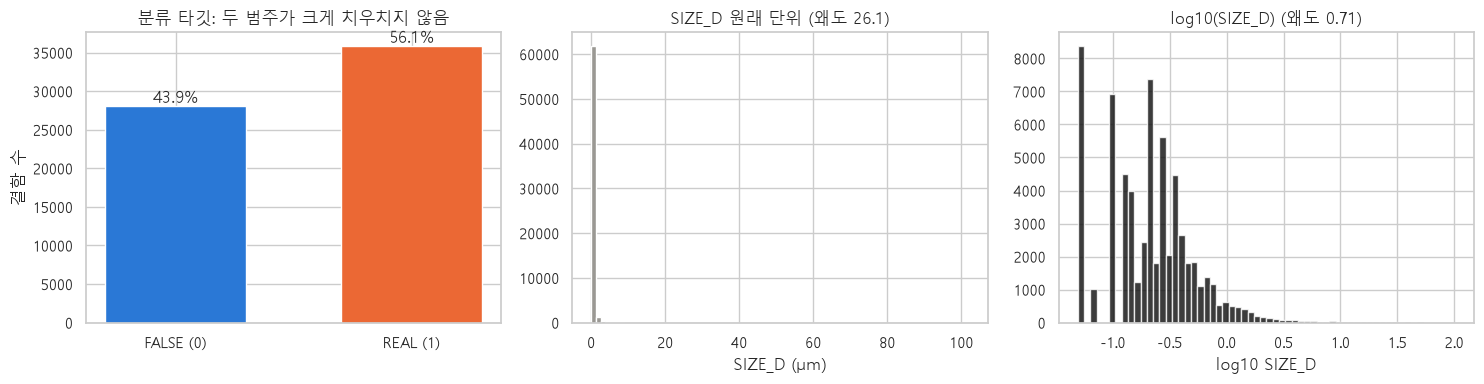

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

cnt = df["is_real"].value_counts().sort_index()
bars = axes[0].bar(["FALSE (0)", "REAL (1)"], cnt.values, color=[C_FALSE, C_REAL], width=0.6)
for b, v in zip(bars, cnt.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v, f"{v / cnt.sum():.1%}", ha="center", va="bottom")
axes[0].set_title("분류 타깃: 두 범주가 크게 치우치지 않음"); axes[0].set_ylabel("결함 수")

axes[1].hist(df["SIZE_D"], bins=80, color=C_GRAY)
axes[1].set_title(f"SIZE_D 원래 단위 (왜도 {df['SIZE_D'].skew():.1f})"); axes[1].set_xlabel("SIZE_D (µm)")

axes[2].hist(df["log_size"], bins=60, color=C_INK, alpha=0.8)
axes[2].set_title(f"log10(SIZE_D) (왜도 {df['log_size'].skew():.2f})"); axes[2].set_xlabel("log10 SIZE_D")
plt.tight_layout(); plt.show()

> **결과 해석**
> - 분류 타깃은 REAL 56% : FALSE 44%로 **심한 불균형은 아닙니다.** 그래도 정확도만 보면 "모두 REAL"도 56%가 나오므로 기준 모델과 비교가 필요합니다.
> - SIZE_D는 오른쪽 꼬리가 아주 긴 분포(최대 약 100µm)입니다. 그대로 학습하면 소수의 큰 결함이 오차를 지배하므로 **log10으로 변환해서 학습**합니다.

---
# 3장. 데이터 분할 & 전처리 파이프라인

> **이 장의 목표**
> - 학습/검증/테스트 데이터의 역할과 교차검증을 설명할 수 있다.
> - 같은 로트가 섞이면 성능이 부풀려지는 이유(그룹 누수)를 이해한다.
> - Pipeline으로 전처리 누수를 막는다.

## 3-1. 데이터를 나누는 이유

```
 전체 데이터 (로트 457개)
 ├── 학습용 80% ──────────────────────────────┐   ← 모델 선택·튜닝·임계값 결정
 │    └─ 교차검증 (GroupKFold 5겹)            │
 │        [검증][학습][학습][학습][학습]  1회차 │
 │        [학습][검증][학습][학습][학습]  2회차 │
 │        ...                    5회 평균 점수 │
 └── 테스트용 20% ── 마지막에 단 한 번 ─────┘   ← "처음 보는 로트"에서의 성능
```

| 데이터 | 용도 | 주의 |
|---|---|---|
| **학습 (train)** | 모델이 규칙을 배움 | |
| **검증 (validation / 교차검증)** | 모델·하이퍼파라미터·임계값 선택 | 여러 번 사용 가능 |
| **테스트 (test)** | 최종 성능 보고 | **딱 한 번**. 보고 나서 모델을 바꾸면 테스트가 아님 |

### 왜 '로트' 단위로 나누나? — 그룹 누수
같은 로트의 웨이퍼는 같은 장비·같은 날·같은 조건을 거쳐 결함 특성이 비슷합니다.
행을 무작위로 나누면 **같은 로트의 형제 결함이 학습과 테스트에 동시에** 들어가서 모델이 "로트의 특징"을 외워 점수가 부풀려집니다.
실제 운영에서는 **새로 들어오는 로트**를 판정해야 하므로, 로트 단위로 나눠야 정직한 점수입니다.

**프롬프트 P07**
```text
[맥락] df, FEAT_CLF, FEAT_REG, is_real, log_size가 준비되어 있어. 로트 열은 'Lot Name'이야.
[작업]
1. GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)로
   'Lot Name' 기준 학습/테스트 인덱스(idx_tr, idx_te)를 만들어줘.
2. 분류용 Xc_tr, Xc_te, yc_tr, yc_te / 회귀용 Xr_tr, Xr_te, yr_tr, yr_te,
   학습용 그룹 g_tr(Lot Name)을 만들어줘. 두 과제는 같은 분할을 공유해.
3. 범주형이 아닌 정수형 열은 float로 바꿔줘 (부분 의존도 함수가 정수 열을 지원하지 않음).
4. 검증: 학습·테스트 로트가 겹치는지(교집합 개수) 확인해줘.
[출력] 표: 구분(학습/테스트)별 행 수, 로트 수, REAL 비율(%), log_size 평균. + 겹치는 로트 수.
```

In [7]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
idx_tr, idx_te = next(gss.split(df, groups=df["Lot Name"]))
tr, te = df.iloc[idx_tr], df.iloc[idx_te]

# ── 분류 / 회귀 데이터 (같은 분할 공유) ──
# 정수형 수치 열은 실수형으로 (부분 의존도 등 일부 sklearn 기능이 정수 열을 지원하지 않음)
to_float = lambda X: X.astype({c: float for c in X.columns if c not in CAT_COLS})
Xc_tr, Xc_te = to_float(tr[FEAT_CLF]), to_float(te[FEAT_CLF])
yc_tr, yc_te = tr["is_real"], te["is_real"]
Xr_tr, Xr_te = to_float(tr[FEAT_REG]), to_float(te[FEAT_REG])
yr_tr, yr_te = tr["log_size"], te["log_size"]
g_tr = tr["Lot Name"]                          # 교차검증용 그룹

overlap = set(tr["Lot Name"]) & set(te["Lot Name"])
split_tbl = pd.DataFrame({
    "행 수": [len(tr), len(te)],
    "로트 수": [tr["Lot Name"].nunique(), te["Lot Name"].nunique()],
    "REAL 비율(%)": [yc_tr.mean() * 100, yc_te.mean() * 100],
    "log_size 평균": [yr_tr.mean(), yr_te.mean()]}, index=["학습", "테스트"])
display(split_tbl.round(3))
print("학습·테스트에 동시에 있는 로트 수 :", len(overlap))

,행 수,로트 수,REAL 비율(%),log_size 평균
학습,52004,365,56.2880,-0.6780
테스트,11883,92,55.2470,-0.7000


학습·테스트에 동시에 있는 로트 수 : 0


> **결과 해석**
> - 겹치는 로트가 0개이므로 테스트는 **처음 보는 로트**입니다.
> - 학습과 테스트의 REAL 비율·평균 크기가 비슷하면 분할이 한쪽으로 치우치지 않은 것입니다.

## 3-2. 전처리 파이프라인 — 전처리도 '학습'이다

| 전처리 | 왜 필요한가 | 어떤 모델에 |
|---|---|---|
| **원-핫 인코딩** | 범주(PC/RMG/CBCMP)를 0/1 열로 바꿈. 숫자 코드(1,2,3)로 두면 "크기 순서"로 오해 | 모든 모델 |
| **표준화 (StandardScaler)** | (x − 평균) / 표준편차. 단위가 다른 변수를 같은 척도로 | 선형 모델 (트리는 불필요) |

**스케일러의 평균·표준편차도 데이터에서 '배운' 값**입니다. 전체 데이터로 `fit` 하면 테스트 정보가 학습에 새어 들어갑니다.
→ `Pipeline` 으로 묶으면 교차검증의 각 회차마다 **학습 부분으로만** fit 되어 자동으로 안전합니다.

```
Pipeline ─┬─ ColumnTransformer ─┬─ 수치형 → StandardScaler (선형 모델만)
          │                     └─ 범주형 → OneHotEncoder
          └─ 모델 (LogisticRegression, RandomForest, ...)
```

**프롬프트 P08**
```text
[맥락] 범주형 열 리스트 CAT_COLS = ['Step_desc', 'POLARITY']가 있어.
[작업] 전처리기를 만드는 함수 make_prep(features, scale)를 작성해줘.
- features 중 CAT_COLS에 있는 열은 OneHotEncoder(handle_unknown='ignore', sparse_output=False),
  나머지 수치형 열은 scale=True면 StandardScaler, False면 그대로 통과('passthrough').
- ColumnTransformer의 verbose_feature_names_out=False로 해서 열 이름이 깔끔하게 나오게 해줘.
[검증] make_prep(FEAT_CLF, True)를 Xc_tr에 fit_transform 해서
1. 변환 전/후 열 개수, 2. 변환 후 열 이름, 3. 수치형 열 3개의 평균·표준편차(≈0, 1인지)를 출력해줘.
```

In [8]:
def make_prep(features, scale=True):
    cat = [c for c in features if c in CAT_COLS]
    num = [c for c in features if c not in CAT_COLS]
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)],
        verbose_feature_names_out=False)

prep = make_prep(FEAT_CLF, scale=True)
Z = pd.DataFrame(prep.fit_transform(Xc_tr), columns=prep.get_feature_names_out())
print(f"변환 전 {Xc_tr.shape[1]}열 → 변환 후 {Z.shape[1]}열")
print("변환 후 열 이름 :", list(Z.columns))
Z[["SIZE_D", "INTENSITY", "RADIUS"]].agg(["mean", "std"]).round(3)

변환 전 19열 → 변환 후 23열
변환 후 열 이름 : ['SIZE_X', 'SIZE_Y', 'DEFECT_AREA', 'SIZE_D', 'INTENSITY', 'ENERGY_PARAM', 'MDAT_OFFSET', 'MDAT_GL', 'MDAT_NOISE', 'RELATIVEMAGNITUDE', 'PATCHDEFECTSIGNAL', 'ALIGNRATIO', 'SPOTLIKENESS', 'PATCHNOISE', 'ACTIVERATIO', 'RADIUS', 'ANGLE', 'Step_desc_CBCMP', 'Step_desc_PC', 'Step_desc_RMG', 'POLARITY_-1', 'POLARITY_0', 'POLARITY_1']


,SIZE_D,INTENSITY,RADIUS
mean,-0.0000,0.0000,-0.0000
std,1.0000,1.0000,1.0000


> **결과 해석**
> - 범주형 2개(공정 3종, 극성 3종)가 6개의 0/1 열로 바뀌어 열 수가 늘었습니다.
> - 표준화된 열은 평균 0, 표준편차 1이 됩니다. 이 값은 **학습 데이터로만** 계산되었고, 테스트에는 같은 평균·표준편차가 그대로 적용됩니다.

**프롬프트 P09**
```text
[맥락] Xc_tr, yc_tr, g_tr(로트), make_prep 함수가 있어.
[작업] '그룹 누수'가 점수를 얼마나 부풀리는지 실험해줘.
- 모델: Pipeline(make_prep(FEAT_CLF, False) + HistGradientBoostingClassifier(random_state=RANDOM_STATE))
- 방법 A: KFold(5, shuffle=True, random_state=RANDOM_STATE) — 행 무작위 분할
- 방법 B: GroupKFold(5) + groups=g_tr — 로트 단위 분할
- 지표: ROC-AUC, 정확도
[출력] 방법별 평균·표준편차 표와 "무작위 분할이 AUC를 x.xxx 높게 추정" 한 줄.
```

In [9]:
hgb_clf = Pipeline([("prep", make_prep(FEAT_CLF, scale=False)),
                    ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE))])
gkf = GroupKFold(n_splits=5)

res = {}
for name, cv, grp in [("A. 무작위 KFold", KFold(5, shuffle=True, random_state=RANDOM_STATE), None),
                      ("B. 로트 GroupKFold", gkf, g_tr)]:
    r = cross_validate(hgb_clf, Xc_tr, yc_tr, cv=cv, groups=grp,
                       scoring=["roc_auc", "accuracy"], n_jobs=-1)
    res[name] = {"AUC 평균": r["test_roc_auc"].mean(), "AUC 표준편차": r["test_roc_auc"].std(),
                 "정확도 평균": r["test_accuracy"].mean()}
leak_tbl = pd.DataFrame(res).T
display(leak_tbl.round(4))
gap = leak_tbl.iloc[0]["AUC 평균"] - leak_tbl.iloc[1]["AUC 평균"]
print(f"무작위 분할이 AUC를 {gap:.4f} 높게 추정")

,AUC 평균,AUC 표준편차,정확도 평균
A. 무작위 KFold,0.9507,0.0028,0.8918
B. 로트 GroupKFold,0.9493,0.0064,0.8913


무작위 분할이 AUC를 0.0014 높게 추정


> **결과 해석**
> - 이 데이터에서는 무작위 분할(0.9507)과 로트 분할(0.9493)의 AUC 차이가 **0.0014로 작습니다.** 결함 하나하나의 신호가 로트 특성보다 훨씬 강하다는 뜻입니다.
> - 하지만 **표준편차는 0.0028 → 0.0064로 2배 이상** 커졌습니다. 로트가 바뀌면 성능이 더 크게 흔들린다는 현실을 무작위 분할은 숨깁니다.
> - 차이가 작게 나온 것은 이 데이터의 결과일 뿐입니다. 설비·로트 효과가 강한 데이터에서는 차이가 훨씬 커질 수 있으므로, **운영 상황(새 로트 판정)과 같은 방식으로 검증하는 원칙**을 지킵니다.

---
# 4장. 평가지표 선택

> **이 장의 목표**
> - 분류·회귀 지표의 정의와 계산법을 안다.
> - 문제의 목적(비용)에 맞는 지표를 고를 수 있다.

## 4-1. 분류 지표 — 혼동행렬에서 시작

```
                       예측
                 FALSE(0)     REAL(1)
 실제 FALSE(0) │   TN     │    FP    │   ← FP: 가성을 진성으로 → 쓸데없는 리뷰 (비용 小)
 실제 REAL(1)  │   FN     │    TP    │   ← FN: 진성을 놓침 → 불량 유출 (비용 大)
```

| 지표 | 공식 | 질문 | 이 문제에서 |
|---|---|---|---|
| **정확도 Accuracy** | (TP+TN) / 전체 | 전체 중 몇 % 맞혔나? | 범주 비율에 속기 쉬움 |
| **정밀도 Precision** | TP / (TP+FP) | REAL이라 한 것 중 진짜 REAL은? | 리뷰 효율 |
| **재현율 Recall (민감도)** | TP / (TP+FN) | 진짜 REAL 중 몇 %를 잡았나? | **놓치면 안 됨** |
| **특이도 Specificity** | TN / (TN+FP) | 진짜 FALSE 중 몇 %를 걸러냈나? | **리뷰 절감률** |
| **F1** | 2·P·R / (P+R) | 정밀도와 재현율의 조화평균 | 임계값 하나에서의 요약 |
| **ROC-AUC** | ROC 곡선 아래 면적 | 무작위 REAL 1개가 무작위 FALSE 1개보다 높은 점수를 받을 확률 | **모델 비교** (임계값 무관) |
| **PR-AUC (AP)** | PR 곡선 아래 면적 | 정밀도-재현율 균형 전체 | 불균형이 클 때 유용 |

## 4-2. 회귀 지표

| 지표 | 공식 | 단위 | 특징 |
|---|---|---|---|
| **MAE** | 평균 \|y − ŷ\| | µm | 직관적, 이상치에 덜 민감 |
| **RMSE** | √평균(y − ŷ)² | µm | 큰 오차에 벌점 ↑ (이상치에 민감) |
| **R² (결정계수)** | 1 − SSE / SST | 없음 | "평균으로 예측" 대비 몇 % 설명했나. 0=기준모델, 1=완벽 |
| **MdAPE** | 중앙값 \|y − ŷ\| / y × 100 | % | 상대 오차. 0.1µm와 10µm 결함을 공평하게 |

**프롬프트 P10**
```text
[작업] 혼동행렬과 분류 지표를 손으로 계산하는 연습 코드를 만들어줘.
- 실제값 y_true = [1,1,1,1,1,1,0,0,0,0], 예측값 y_pred = [1,1,1,1,0,0,1,0,0,0]
1. TP, FP, FN, TN을 numpy 비교 연산으로 직접 세줘.
2. 정확도, 정밀도, 재현율, 특이도, F1을 공식으로 직접 계산해줘.
3. 같은 값을 sklearn(accuracy_score, precision_score, recall_score, f1_score)으로 계산해
   '직접 계산'과 'sklearn' 두 열로 나란히 비교하는 표를 만들어줘 (특이도는 recall_score(pos_label=0)).
```

In [10]:
y_true = np.array([1, 1, 1, 1, 1, 1, 0, 0, 0, 0])
y_pred = np.array([1, 1, 1, 1, 0, 0, 1, 0, 0, 0])

TP = ((y_true == 1) & (y_pred == 1)).sum(); FN = ((y_true == 1) & (y_pred == 0)).sum()
FP = ((y_true == 0) & (y_pred == 1)).sum(); TN = ((y_true == 0) & (y_pred == 0)).sum()
print(f"TP={TP}, FN={FN}, FP={FP}, TN={TN}")

prec, rec = TP / (TP + FP), TP / (TP + FN)
manual = {"정확도": (TP + TN) / len(y_true), "정밀도": prec, "재현율": rec,
          "특이도": TN / (TN + FP), "F1": 2 * prec * rec / (prec + rec)}
skl = {"정확도": accuracy_score(y_true, y_pred), "정밀도": precision_score(y_true, y_pred),
       "재현율": recall_score(y_true, y_pred), "특이도": recall_score(y_true, y_pred, pos_label=0),
       "F1": f1_score(y_true, y_pred)}
pd.DataFrame({"직접 계산": manual, "sklearn": skl}).round(3)

TP=4, FN=2, FP=1, TN=3


,직접 계산,sklearn
정확도,0.7000,0.7000
정밀도,0.8000,0.8000
재현율,0.6670,0.6670
특이도,0.7500,0.7500
F1,0.7270,0.7270


**프롬프트 P11**
```text
[맥락] Xc_tr, yc_tr(REAL 56%)가 있어.
[작업] '정확도의 함정'을 보여줘.
- DummyClassifier(strategy='most_frequent')로 모두 REAL이라고 예측하는 모델을 학습 데이터로 fit.
- 같은 학습 데이터에서 정확도, 재현율, 특이도, F1, ROC-AUC를 계산해 한 줄 표로.
  (ROC-AUC는 predict_proba의 1열 사용)
[출력] 표 + "아무것도 배우지 않아도 정확도 xx%" 한 줄.
```

In [11]:
dummy = DummyClassifier(strategy="most_frequent").fit(Xc_tr, yc_tr)
p = dummy.predict(Xc_tr)
pd.DataFrame([{"정확도": accuracy_score(yc_tr, p), "재현율(REAL)": recall_score(yc_tr, p),
               "특이도(FALSE)": recall_score(yc_tr, p, pos_label=0), "F1": f1_score(yc_tr, p),
               "ROC-AUC": roc_auc_score(yc_tr, dummy.predict_proba(Xc_tr)[:, 1])}],
             index=["Dummy(모두 REAL)"]).round(3)

,정확도,재현율(REAL),특이도(FALSE),F1,ROC-AUC
Dummy(모두 REAL),0.5630,1.0000,0.0000,0.7200,0.5000


> **결과 해석**
> - "모두 REAL"이라고만 해도 정확도 56%, 재현율 100%입니다. 하지만 **특이도 0%** — 가성결함을 하나도 걸러내지 못해 리뷰 절감 효과가 전혀 없습니다.
> - ROC-AUC 0.5는 "동전 던지기" 수준입니다. → **정확도·재현율 하나만 보면 안 되고, 반드시 기준 모델과 비교**해야 합니다.

**프롬프트 P12**
```text
[작업] 회귀 지표 MAE와 RMSE가 이상치에 어떻게 다르게 반응하는지 보여줘.
- 실제값 y = [0.10, 0.15, 0.20, 0.25, 0.30] (µm)
- 예측 A = 실제값 + 0.05 (모든 점에서 조금씩 틀림)
- 예측 B = 실제값과 같고 마지막 하나만 0.30 → 0.55 (한 점만 크게 틀림)
- 각 예측의 MAE, RMSE, R²를 계산해 표로 비교해줘.
[출력] 표 + 해석 2줄 (오차 총합이 같아도 RMSE는 B를 더 나쁘게 본다).
```

In [12]:
y = np.array([0.10, 0.15, 0.20, 0.25, 0.30])
pred_A = y + 0.05
pred_B = y.copy(); pred_B[-1] = 0.55

pd.DataFrame({name: {"MAE": mean_absolute_error(y, p), "RMSE": root_mean_squared_error(y, p),
                     "R²": r2_score(y, p)}
              for name, p in [("A: 모두 0.05씩", pred_A), ("B: 한 점만 0.25", pred_B)]}).T.round(4)

,MAE,RMSE,R²
A: 모두 0.05씩,0.0500,0.0500,0.5000
B: 한 점만 0.25,0.0500,0.1118,-1.5000


> **결과 해석**
> - 두 예측 모두 오차의 합은 0.25로 같으므로 **MAE는 0.05로 같습니다.** 반면 **RMSE는 오차를 제곱하므로 B를 2배 이상 나쁘게** 봅니다.
> - SIZE_D처럼 큰 값이 드물게 있는 데이터에서는 RMSE가 소수의 큰 결함에 좌우됩니다. 그래서 이 노트북은 **MAE와 상대오차(MdAPE)를 주 지표**로, RMSE는 보조로 봅니다.

## 4-3. 이 노트북의 지표 선택 (결정 사항)

| 과제 | 단계 | 지표 | 선택 이유 |
|---|---|---|---|
| **분류** | 모델 비교·튜닝 | **ROC-AUC** (보조: PR-AUC, F1) | 임계값과 무관하게 "REAL을 FALSE보다 높게 점수 매기는 능력"을 비교. 범주 비율 56:44에서 안정적 |
| | 운영 임계값 | **재현율(REAL) ≥ 98% 조건에서 특이도 최대** | 진성결함 놓침(FN)은 불량 유출 → 비용이 큼. 그 조건 안에서 가성결함을 최대한 걸러 리뷰 공수 절감 |
| **회귀** | 학습 | log10(SIZE_D) | 긴 꼬리 분포 → 로그로 오차를 상대적으로 만듦 |
| | 모델 비교 | **R²(로그 척도)**, **MAE(µm)**, **MdAPE(%)** | R²: 기준 모델 대비 설명력 / MAE: 현장 단위 / MdAPE: 크기와 무관한 상대 오차 |
| | 보조 | RMSE(µm) | 큰 결함에서의 대형 오차 감시 |

---
# 5장. 분류 모델링 — 진성/가성결함 판정

> **이 장의 목표**
> - 기준 모델부터 앙상블까지 교차검증으로 공정하게 비교한다.
> - 과적합 곡선과 학습 곡선을 읽는다.
> - 하이퍼파라미터를 튜닝하고 테스트 데이터로 최종 평가한다.
> - 현장 목적에 맞는 임계값을 정하고 오차를 분석한다.

**프롬프트 P13**
```text
[맥락] make_prep(features, scale), FEAT_CLF, RANDOM_STATE가 있어.
[작업] 비교할 분류 모델 5개를 딕셔너리 clf_models로 만들어줘. 모두 Pipeline(prep + model) 형태.
1. 'Dummy'           : DummyClassifier(strategy='prior')                  — prep scale=False
2. '로지스틱 회귀'    : LogisticRegression(max_iter=2000)                  — prep scale=True (선형 모델은 표준화 필요)
3. '의사결정나무'     : DecisionTreeClassifier(max_depth=8)                — scale=False
4. '랜덤포레스트'     : RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1) — scale=False
5. '그래디언트부스팅' : HistGradientBoostingClassifier()                   — scale=False
모든 모델에 random_state=RANDOM_STATE (Dummy·로지스틱 제외).
[출력] 모델 이름과 Pipeline 구조를 출력해줘.
```

In [13]:
def clf_pipe(model, scale=False, features=FEAT_CLF):
    return Pipeline([("prep", make_prep(features, scale)), ("model", model)])

clf_models = {
    "Dummy":         clf_pipe(DummyClassifier(strategy="prior")),
    "로지스틱 회귀":    clf_pipe(LogisticRegression(max_iter=2000), scale=True),
    "의사결정나무":     clf_pipe(DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE)),
    "랜덤포레스트":     clf_pipe(RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                                n_jobs=-1, random_state=RANDOM_STATE)),
    "그래디언트부스팅": clf_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
}
for name, m in clf_models.items():
    print(f"{name:10s} → {[type(s).__name__ for _, s in m.steps]}")

Dummy      → ['ColumnTransformer', 'DummyClassifier']
로지스틱 회귀    → ['ColumnTransformer', 'LogisticRegression']
의사결정나무     → ['ColumnTransformer', 'DecisionTreeClassifier']
랜덤포레스트     → ['ColumnTransformer', 'RandomForestClassifier']
그래디언트부스팅   → ['ColumnTransformer', 'HistGradientBoostingClassifier']


**프롬프트 P14**
```text
[맥락] clf_models(5개 Pipeline), Xc_tr, yc_tr, g_tr, gkf = GroupKFold(5)가 있어.
[작업] 교차검증으로 모델을 공정하게 비교하는 함수 cv_compare(models, X, y, groups, scoring, main)를 만들어줘.
- cross_validate(..., cv=gkf, groups=groups, scoring=scoring, return_train_score=True)
- 결과: 모델별 각 지표의 검증 평균, 주 지표(main)의 검증 표준편차, 주 지표의 학습 평균,
  과적합 간격(학습-검증), 학습 시간(초, fit_time 평균)
- 회귀에서 neg_ 지표를 쓸 때도 쓸 수 있도록, 값이 음수인 지표는 부호를 뒤집어 양수로 보여줘.
[실행] 분류 scoring = {'AUC':'roc_auc', 'PR_AUC':'average_precision', 'F1':'f1', '정확도':'accuracy'},
       main='AUC'로 clf_models를 비교하고 AUC 내림차순으로 정렬해줘.
[출력] 소수점 4자리 표.
```

In [14]:
def cv_compare(models, X, y, groups, scoring, main):
    rows = {}
    for name, m in models.items():
        r = cross_validate(m, X, y, cv=gkf, groups=groups, scoring=scoring,
                           return_train_score=True, n_jobs=-1)
        row = {k: abs(r[f"test_{k}"].mean()) for k in scoring}
        row[f"{main}_표준편차"] = r[f"test_{main}"].std()
        row[f"{main}_학습"] = abs(r[f"train_{main}"].mean())
        row["과적합 간격"] = row[f"{main}_학습"] - row[main]
        row["학습시간(초)"] = r["fit_time"].mean()
        rows[name] = row
    return pd.DataFrame(rows).T

SCORING_CLF = {"AUC": "roc_auc", "PR_AUC": "average_precision", "F1": "f1", "정확도": "accuracy"}
t0 = time.time()
clf_cv = cv_compare(clf_models, Xc_tr, yc_tr, g_tr, SCORING_CLF, main="AUC").sort_values("AUC", ascending=False)
print(f"교차검증 소요 {time.time() - t0:.0f}초")
clf_cv.round(4)

교차검증 소요 32초


,AUC,PR_AUC,F1,정확도,AUC_표준편차,AUC_학습,과적합 간격,학습시간(초)
그래디언트부스팅,0.9493,0.9517,0.9066,0.8913,0.0064,0.9651,0.0158,2.2701
랜덤포레스트,0.9492,0.9505,0.9085,0.8931,0.0074,0.9993,0.0500,22.2608
의사결정나무,0.9025,0.8792,0.8880,0.8660,0.0109,0.9158,0.0133,0.6060
로지스틱 회귀,0.8425,0.8448,0.8001,0.7607,0.0135,0.8450,0.0025,0.3908
Dummy,0.5000,0.5629,0.7199,0.5629,0.0000,0.5000,0.0000,0.0463


**프롬프트 P15**
```text
[맥락] clf_cv 표(모델별 AUC, AUC_표준편차, AUC_학습)가 있어.
[작업] 모델 비교 막대그래프를 그려줘.
- 가로 막대: 모델별 검증 AUC, 오차막대 = AUC_표준편차, 가장 좋은 모델만 주황(C_REAL), 나머지 회색.
- 같은 축에 학습 AUC를 작은 검은 점(◆)으로 표시해 과적합 간격이 보이게.
- 막대 끝에 검증 AUC 값(소수 3자리) 표시, x축 0.4~1.02.
- 제목에 결론을 써줘 (예: '그래디언트부스팅이 가장 높고, 의사결정나무는 과적합').
```

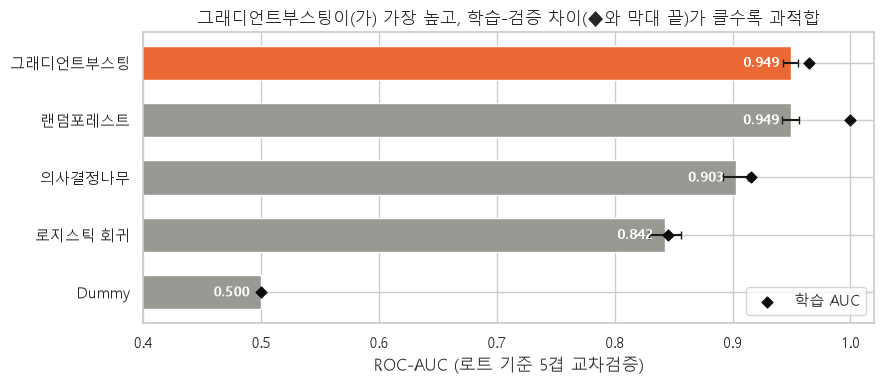

In [15]:
s = clf_cv.sort_values("AUC")
colors = [C_REAL if n == s["AUC"].idxmax() else C_GRAY for n in s.index]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(s.index, s["AUC"], xerr=s["AUC_표준편차"], color=colors, height=0.6, capsize=3)
ax.scatter(s["AUC_학습"], s.index, marker="D", color=C_INK, s=30, zorder=3, label="학습 AUC")
for i, v in enumerate(s["AUC"]):
    ax.text(v - 0.01, i, f"{v:.3f}", va="center", ha="right", color="white", fontsize=10, fontweight="bold")
ax.set_xlim(0.4, 1.02); ax.set_xlabel("ROC-AUC (로트 기준 5겹 교차검증)")
ax.set_title(f"{s['AUC'].idxmax()}이(가) 가장 높고, 학습-검증 차이(◆와 막대 끝)가 클수록 과적합")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

> **결과 해석**
> - **그래디언트부스팅(0.949)과 랜덤포레스트(0.949)가 사실상 동률**이고, 의사결정나무(0.903) → 로지스틱(0.842) → Dummy(0.500) 순입니다.
> - 랜덤포레스트는 학습 AUC가 0.999로 거의 외웠지만(과적합 간격 0.050) 검증 점수는 여전히 높습니다. 나무 여러 그루의 평균이 과적합을 상쇄하기 때문입니다.
> - 학습 시간은 HGB 약 2초, RF 약 26초로 **HGB가 10배 이상 빠릅니다.** 성능이 같으면 빠르고 가벼운 모델을 고르므로 **HGB를 튜닝 대상으로** 정합니다.
> - 로지스틱 회귀는 학습·검증 점수가 모두 0.84로 과적합은 없지만 **과소적합**입니다. 특성과 정답의 관계가 직선(가중합)으로는 표현되지 않습니다.

## 5-1. 과적합을 눈으로 보기 — 검증 곡선 (Validation Curve)
하이퍼파라미터 하나(나무 깊이)를 바꿔가며 **학습 점수와 검증 점수**를 함께 그리면 과소적합 ↔ 과적합 구간이 보입니다.

**프롬프트 P16**
```text
[맥락] clf_pipe 함수, Xc_tr, yc_tr, g_tr, gkf가 있어.
[작업] 의사결정나무의 max_depth를 1~20으로 바꾸며 validation_curve를 그려줘.
- estimator: clf_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE))
- param_name='model__max_depth', cv=gkf, groups=g_tr, scoring='roc_auc', n_jobs=-1
- 학습 평균(검은 선), 검증 평균(주황 선)과 검증 ±1 표준편차 음영.
- 검증 AUC가 최대인 깊이에 세로 점선과 '최적 깊이 = d' 주석.
[출력] 그래프 + 최적 깊이와 그때의 학습/검증 AUC 출력.
```

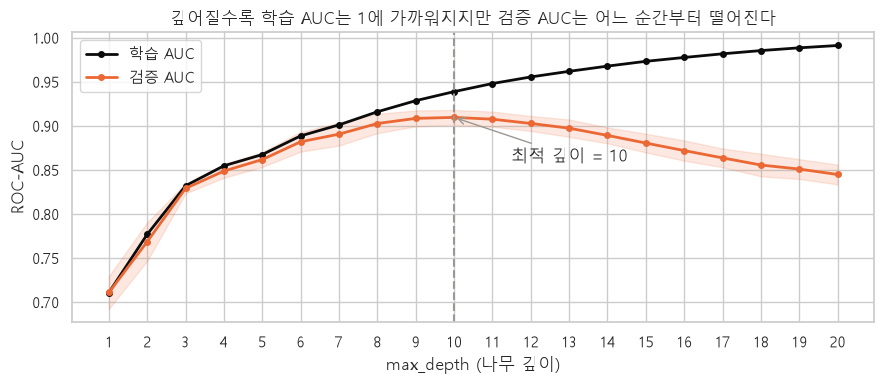

최적 깊이 10: 학습 0.939 / 검증 0.909  |  깊이 20: 학습 0.991 / 검증 0.845


In [16]:
depths = np.arange(1, 21)
tr_sc, va_sc = validation_curve(clf_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)),
                                Xc_tr, yc_tr, param_name="model__max_depth", param_range=depths,
                                cv=gkf, groups=g_tr, scoring="roc_auc", n_jobs=-1)
tr_m, va_m, va_s = tr_sc.mean(1), va_sc.mean(1), va_sc.std(1)
best_d = depths[va_m.argmax()]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(depths, tr_m, "-o", color=C_INK, ms=4, lw=2, label="학습 AUC")
ax.plot(depths, va_m, "-o", color=C_REAL, ms=4, lw=2, label="검증 AUC")
ax.fill_between(depths, va_m - va_s, va_m + va_s, color=C_REAL, alpha=0.15)
ax.axvline(best_d, color=C_GRAY, ls="--")
ax.annotate(f"최적 깊이 = {best_d}", (best_d, va_m.max()), xytext=(best_d + 1.5, va_m.max() - 0.05),
            arrowprops=dict(arrowstyle="->", color=C_GRAY))
ax.set_xlabel("max_depth (나무 깊이)"); ax.set_ylabel("ROC-AUC"); ax.set_xticks(depths)
ax.set_title("깊어질수록 학습 AUC는 1에 가까워지지만 검증 AUC는 어느 순간부터 떨어진다")
ax.legend(); plt.tight_layout(); plt.show()
print(f"최적 깊이 {best_d}: 학습 {tr_m[va_m.argmax()]:.3f} / 검증 {va_m.max():.3f}  |  깊이 20: 학습 {tr_m[-1]:.3f} / 검증 {va_m[-1]:.3f}")

> **결과 해석**
> - 깊이 1~10에서는 학습·검증 AUC가 함께 오릅니다(과소적합 구간). **깊이 10에서 검증 AUC가 0.909로 최고**입니다.
> - 그 뒤로는 학습 AUC가 0.99까지 오르는 동안 **검증 AUC는 0.845로 떨어집니다.** 이것이 과적합입니다.
> - 앞에서 쓴 `max_depth=8`은 최적점 근처였습니다. 하이퍼파라미터는 감으로 정하지 않고 이렇게 **검증 점수로** 정합니다.

**프롬프트 P17**
```text
[맥락] clf_models['그래디언트부스팅'], Xc_tr, yc_tr, g_tr, gkf가 있어.
[작업] 학습 데이터 양에 따른 성능 변화를 learning_curve로 그려줘.
- train_sizes = [0.05, 0.1, 0.2, 0.4, 0.7, 1.0], cv=gkf, groups=g_tr, scoring='roc_auc', n_jobs=-1
- x축: 학습에 쓴 결함 수, 학습 AUC(검은 선)와 검증 AUC(주황 선, ±1 표준편차 음영)
- 제목에 결론: 데이터를 더 모으면 좋아질지 판단
[출력] 그래프 + 크기별 검증 AUC 표.
```

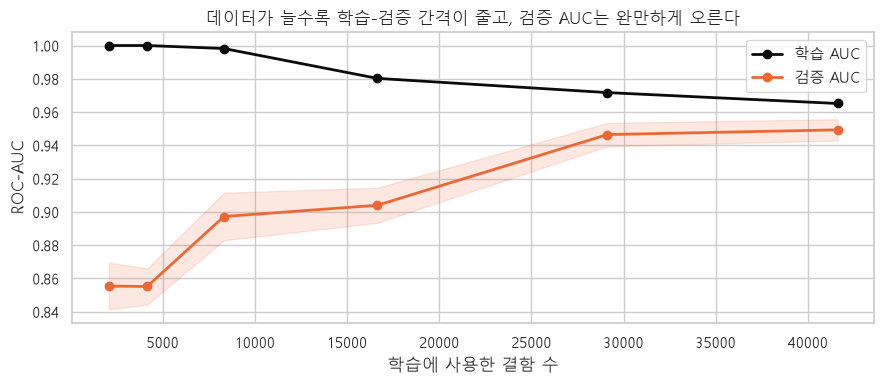

,학습 결함 수,학습 AUC,검증 AUC
0,2080,1.0000,0.8554
1,4161,1.0000,0.8552
2,8322,0.9982,0.8972
3,16644,0.9803,0.9040
4,29128,0.9717,0.9465
5,41612,0.9652,0.9493


In [17]:
sizes, tr_sc, va_sc = learning_curve(clf_models["그래디언트부스팅"], Xc_tr, yc_tr, groups=g_tr, cv=gkf,
                                     train_sizes=[0.05, 0.1, 0.2, 0.4, 0.7, 1.0],
                                     scoring="roc_auc", n_jobs=-1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sizes, tr_sc.mean(1), "-o", color=C_INK, lw=2, label="학습 AUC")
ax.plot(sizes, va_sc.mean(1), "-o", color=C_REAL, lw=2, label="검증 AUC")
ax.fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), color=C_REAL, alpha=0.15)
ax.set_xlabel("학습에 사용한 결함 수"); ax.set_ylabel("ROC-AUC")
ax.set_title("데이터가 늘수록 학습-검증 간격이 줄고, 검증 AUC는 완만하게 오른다")
ax.legend(); plt.tight_layout(); plt.show()
pd.DataFrame({"학습 결함 수": sizes, "학습 AUC": tr_sc.mean(1), "검증 AUC": va_sc.mean(1)}).round(4)

> **결과 해석**
> - 데이터가 적을 때(약 2천 개)는 학습 AUC 1.0, 검증 0.855로 **과적합이 심합니다.**
> - 데이터가 늘수록 간격이 줄어 약 4만 개에서 학습 0.965 / 검증 0.949가 됩니다. 마지막 구간의 상승폭(0.9465 → 0.9493)이 작아 **곡선이 거의 평평해졌습니다.**
> - 따라서 같은 종류의 데이터를 더 모아서 얻을 이득은 작습니다. 성능을 더 올리려면 **새로운 정보(새 특성)** 가 필요합니다.

## 5-2. 하이퍼파라미터 튜닝 — RandomizedSearchCV
가능한 조합을 전부 시험(Grid)하면 오래 걸리므로, **무작위로 일부 조합만** 뽑아 교차검증합니다.

| 하이퍼파라미터 | 뜻 | 크면 |
|---|---|---|
| `learning_rate` | 나무 하나가 오차를 얼마나 고칠지 | 빠르지만 과적합 위험 |
| `max_leaf_nodes` | 나무 하나의 잎 개수 (복잡도) | 복잡한 패턴, 과적합 위험 |
| `min_samples_leaf` | 잎 하나의 최소 표본 수 | 단순해짐 (규제) |
| `l2_regularization` | 가중치 규제 | 단순해짐 (규제) |
| `max_iter` | 나무 개수 (조기 종료 시 최대값) | 더 오래 학습 |

**프롬프트 P18**
```text
[맥락] clf_pipe, Xc_tr, yc_tr, g_tr, gkf가 있어.
[작업] 그래디언트부스팅 분류기를 RandomizedSearchCV로 튜닝해줘.
- 기본 모델: clf_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE))
- 탐색 공간 (Pipeline이므로 'model__' 접두사):
  learning_rate [0.03, 0.05, 0.1, 0.2], max_leaf_nodes [15, 31, 63, 127],
  min_samples_leaf [10, 20, 50, 100], l2_regularization [0, 0.1, 1.0], max_iter [200, 400, 800]
- n_iter=15, cv=gkf, scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=-1, fit 시 groups=g_tr
- 테스트 데이터는 절대 사용하지 마.
[출력] 최적 파라미터, 최적 CV AUC, 기본 모델 CV AUC(clf_cv 표)와의 차이,
       상위 5개 조합 표(파라미터 + 평균 AUC + 표준편차).
```

In [18]:
param_clf = {"model__learning_rate": [0.03, 0.05, 0.1, 0.2],
             "model__max_leaf_nodes": [15, 31, 63, 127],
             "model__min_samples_leaf": [10, 20, 50, 100],
             "model__l2_regularization": [0, 0.1, 1.0],
             "model__max_iter": [200, 400, 800]}
search_clf = RandomizedSearchCV(clf_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
                                param_clf, n_iter=15, cv=gkf, scoring="roc_auc",
                                random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.time()
search_clf.fit(Xc_tr, yc_tr, groups=g_tr)
print(f"튜닝 소요 {time.time() - t0:.0f}초")
print("최적 파라미터 :", {k.replace("model__", ""): v for k, v in search_clf.best_params_.items()})
print(f"최적 CV AUC  : {search_clf.best_score_:.4f}  (기본값 {clf_cv.loc['그래디언트부스팅', 'AUC']:.4f}, "
      f"차이 {search_clf.best_score_ - clf_cv.loc['그래디언트부스팅', 'AUC']:+.4f})")

top5 = (pd.DataFrame(search_clf.cv_results_).sort_values("rank_test_score").head(5)
        [[c for c in search_clf.cv_results_ if c.startswith("param_")] + ["mean_test_score", "std_test_score"]])
top5.columns = [c.replace("param_model__", "") for c in top5.columns]
top5.round(4)

튜닝 소요 105초
최적 파라미터 : {'min_samples_leaf': 50, 'max_leaf_nodes': 63, 'max_iter': 800, 'learning_rate': 0.03, 'l2_regularization': 0.1}
최적 CV AUC  : 0.9515  (기본값 0.9493, 차이 +0.0022)


,min_samples_leaf,max_leaf_nodes,max_iter,learning_rate,l2_regularization,mean_test_score,std_test_score
0,50,63,800,0.0300,0.1000,0.9515,0.0066
7,20,127,400,0.0300,0.0000,0.9514,0.0064
12,20,63,800,0.0500,0.1000,0.9511,0.0065
11,100,127,200,0.0500,1.0000,0.9509,0.0067
10,50,31,800,0.0500,1.0000,0.9507,0.0065


> **결과 해석**
> - 튜닝으로 CV AUC가 0.9493 → 0.9515로 **+0.002** 올랐습니다. 상위 5개 조합의 점수 차이도 0.001 이내입니다.
> - 정형 데이터에서 HGB는 **기본값만으로도 이미 좋은** 경우가 많습니다. 튜닝보다 **문제 정의, 누수 제거, 특성 선택**이 성능에 더 큰 영향을 줍니다.
> - 최적 조합은 작은 학습률(0.03)에 나무를 많이(800) 쓰는 형태입니다. "천천히 많이 배우기"가 안정적이라는 일반적인 경향과 같습니다.

## 5-3. 테스트 데이터로 최종 평가 (단 한 번)
지금까지 테스트 데이터는 한 번도 쓰지 않았습니다. 이제 **튜닝된 모델을 학습 데이터 전체로 다시 학습**하고 테스트에서 평가합니다.
비교를 위해 로지스틱 회귀와 랜덤포레스트도 함께 평가합니다.

**프롬프트 P19**
```text
[맥락] search_clf.best_estimator_(튜닝된 HGB, 이미 학습 데이터 전체로 재학습됨), clf_models,
       Xc_tr, yc_tr, Xc_te, yc_te가 있어.
[작업]
1. best_clf = search_clf.best_estimator_ 로 두고, '로지스틱 회귀', '랜덤포레스트', 'Dummy'는 학습 데이터로 fit.
2. 4개 모델의 테스트 예측 확률(1열)을 딕셔너리 proba_te에 저장.
3. 임계값 0.5 기준으로 AUC, PR-AUC, 정확도, 정밀도, 재현율, 특이도, F1을 계산해 표로.
[조건] 지표 계산을 함수 clf_report(y, proba, thr=0.5)로 만들어 재사용할 수 있게 해줘.
[출력] AUC 내림차순 표, 소수점 4자리.
```

In [19]:
def clf_report(y, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"AUC": roc_auc_score(y, proba), "PR_AUC": average_precision_score(y, proba),
            "정확도": accuracy_score(y, pred), "정밀도": precision_score(y, pred, zero_division=0),
            "재현율(REAL)": recall_score(y, pred), "특이도(FALSE)": recall_score(y, pred, pos_label=0),
            "F1": f1_score(y, pred)}

best_clf = search_clf.best_estimator_
final_clf = {"그래디언트부스팅(튜닝)": best_clf}
for name in ["랜덤포레스트", "로지스틱 회귀", "Dummy"]:
    final_clf[name] = clf_models[name].fit(Xc_tr, yc_tr)

proba_te = {name: m.predict_proba(Xc_te)[:, 1] for name, m in final_clf.items()}
test_tbl = pd.DataFrame({n: clf_report(yc_te, p) for n, p in proba_te.items()}).T.sort_values("AUC", ascending=False)
test_tbl.round(4)

,AUC,PR_AUC,정확도,정밀도,재현율(REAL),특이도(FALSE),F1
그래디언트부스팅(튜닝),0.9533,0.9535,0.8982,0.8748,0.9519,0.8319,0.9117
랜덤포레스트,0.9509,0.9493,0.9005,0.8754,0.9560,0.8321,0.9139
로지스틱 회귀,0.8396,0.8298,0.7651,0.7437,0.8772,0.6267,0.8049
Dummy,0.5000,0.5525,0.5525,0.5525,1.0000,0.0000,0.7117


> **결과 해석**
> - 테스트 로트의 AUC는 **0.953**으로 교차검증 값(0.952)과 거의 같습니다. 검증 과정이 정직했다는 증거입니다. 테스트 점수가 CV보다 훨씬 낮았다면 누수나 과적합을 의심해야 합니다.
> - 임계값 0.5에서 **재현율 95.2%, 특이도 83.2%** 입니다. 진성결함 100개 중 약 5개를 놓치는데, 현장 기준(98%)에는 못 미칩니다. → 5-4에서 임계값을 조정합니다.
> - 랜덤포레스트도 거의 같은 성능이지만 무겁고 느리므로 HGB를 최종 모델로 선택합니다.

**프롬프트 P20**
```text
[맥락] yc_te, proba_te['그래디언트부스팅(튜닝)']가 있어.
[작업] 임계값 0.5의 혼동행렬을 1×2로 그려줘.
- 왼쪽: 개수(정수), 오른쪽: 실제 행 기준 비율(%) — 각 행의 합이 100%
- seaborn heatmap, 색은 Blues, 축 라벨은 'FALSE(가성)', 'REAL(진성)', x=예측, y=실제
- 칸 위에 TN/FP/FN/TP 이름이 함께 보이도록 주석을 만들어줘 (예: 'TN\n5,123').
[출력] 그래프 + 놓친 진성결함(FN) 수 한 줄.
```

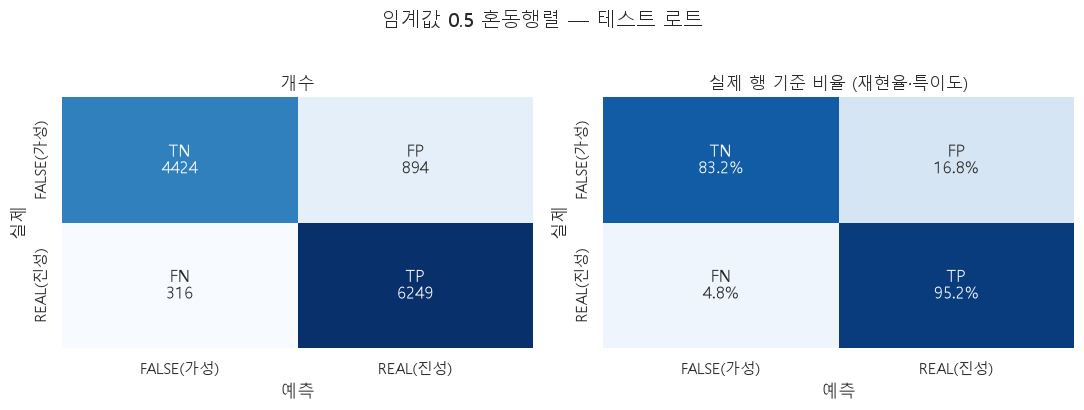

놓친 진성결함(FN) : 316개 / 진성결함 6,565개 중


In [20]:
p_best = proba_te["그래디언트부스팅(튜닝)"]
cm = confusion_matrix(yc_te, (p_best >= 0.5).astype(int))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
names = np.array([["TN", "FP"], ["FN", "TP"]])
labels = ["FALSE(가성)", "REAL(진성)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=np.char.add(names, np.char.mod("\n%d", cm)), fmt="", cmap="Blues", cbar=False,
            xticklabels=labels, yticklabels=labels, ax=axes[0], annot_kws={"size": 12})
sns.heatmap(cm_pct, annot=np.char.add(names, np.char.mod("\n%.1f%%", cm_pct)), fmt="", cmap="Blues",
            cbar=False, vmin=0, vmax=100, xticklabels=labels, yticklabels=labels, ax=axes[1],
            annot_kws={"size": 12})
for ax, t in zip(axes, ["개수", "실제 행 기준 비율 (재현율·특이도)"]):
    ax.set_xlabel("예측"); ax.set_ylabel("실제"); ax.set_title(t)
plt.suptitle("임계값 0.5 혼동행렬 — 테스트 로트", y=1.02); plt.tight_layout(); plt.show()
print(f"놓친 진성결함(FN) : {cm[1, 0]:,}개 / 진성결함 {cm[1].sum():,}개 중")

**프롬프트 P21**
```text
[맥락] yc_te와 proba_te(모델 4개의 테스트 예측 확률)가 있어.
[작업] ROC 곡선과 PR 곡선을 1×2로 그려줘.
- 모델 색 고정: 그래디언트부스팅(튜닝)=주황 C_REAL, 랜덤포레스트=초록 '#1baf7a',
  로지스틱 회귀=파랑 C_FALSE, Dummy=회색 점선.
- 범례에 모델명과 AUC(왼쪽) / AP(오른쪽) 값.
- ROC 왼쪽에 대각선(무작위) 회색 점선, PR 오른쪽에 REAL 비율 수평선(기준선).
- 선 두께 2.
```

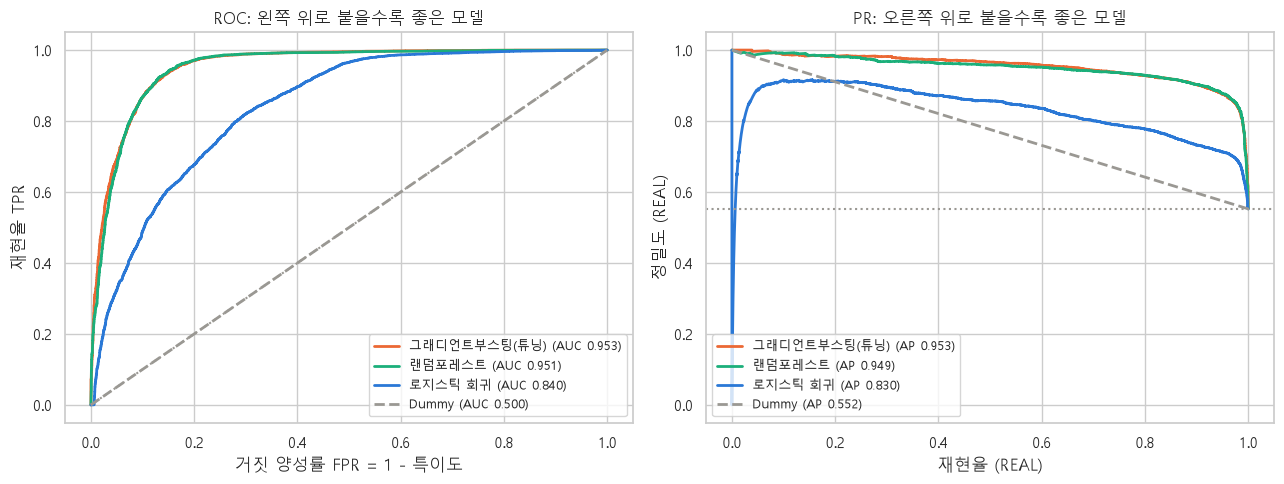

In [21]:
MODEL_COLOR = {"그래디언트부스팅(튜닝)": C_REAL, "랜덤포레스트": "#1baf7a",
               "로지스틱 회귀": C_FALSE, "Dummy": C_GRAY}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in proba_te.items():
    ls = "--" if name == "Dummy" else "-"
    fpr, tpr, _ = roc_curve(yc_te, p)
    axes[0].plot(fpr, tpr, ls, color=MODEL_COLOR[name], lw=2, label=f"{name} (AUC {roc_auc_score(yc_te, p):.3f})")
    pr, rc, _ = precision_recall_curve(yc_te, p)
    axes[1].plot(rc, pr, ls, color=MODEL_COLOR[name], lw=2, label=f"{name} (AP {average_precision_score(yc_te, p):.3f})")
axes[0].plot([0, 1], [0, 1], ":", color=C_GRAY)
axes[0].set_xlabel("거짓 양성률 FPR = 1 - 특이도"); axes[0].set_ylabel("재현율 TPR")
axes[0].set_title("ROC: 왼쪽 위로 붙을수록 좋은 모델")
axes[1].axhline(yc_te.mean(), ls=":", color=C_GRAY)
axes[1].set_xlabel("재현율 (REAL)"); axes[1].set_ylabel("정밀도 (REAL)")
axes[1].set_title("PR: 오른쪽 위로 붙을수록 좋은 모델")
for ax in axes: ax.legend(loc="lower left" if ax is axes[1] else "lower right", fontsize=9)
plt.tight_layout(); plt.show()

> **결과 해석**
> - 트리 앙상블 두 모델의 곡선은 거의 겹치고, 로지스틱 회귀는 확연히 아래에 있습니다. **신호와 결함 종류의 관계가 직선이 아니라는 뜻**입니다.
> - ROC 곡선의 왼쪽 아래 구간(FPR이 작은 곳)과 PR 곡선의 오른쪽 끝(재현율이 높은 곳)이 **운영 임계값을 고를 영역**입니다. → 다음 절.

## 5-4. 임계값 정하기 — 0.5는 정답이 아니다
모델은 확률을 내고, **사람이 정한 임계값**으로 REAL/FALSE를 나눕니다. 4-3에서 정한 기준은
> **"진성결함 재현율 98% 이상을 지키면서, 가성결함을 최대한 많이 걸러낸다(특이도 최대)."**

임계값도 '튜닝'이므로 **테스트가 아닌 학습 데이터의 교차검증 예측(Out-of-Fold)** 으로 정합니다.

**프롬프트 P22**
```text
[맥락] best_clf(튜닝된 Pipeline), Xc_tr, yc_tr, g_tr, gkf가 있어.
[작업]
1. cross_val_predict(best_clf, Xc_tr, yc_tr, groups=g_tr, cv=gkf, method='predict_proba', n_jobs=-1)로
   학습 데이터의 OOF 확률 oof를 구해줘 (각 행은 자기가 검증 fold일 때 예측됨).
2. 임계값 0.01~0.99(0.01 간격)마다 재현율(REAL), 정밀도, 특이도(FALSE)를 계산해 thr_tbl로.
3. 재현율 ≥ 0.98을 만족하는 임계값 중 가장 큰 값(=특이도 최대)을 THR로 정해줘.
4. 세 지표를 임계값에 따라 선 그래프로 그리고(재현율 주황, 특이도 파랑, 정밀도 회색),
   0.98 수평 점선과 THR 세로 점선, 0.5 세로 점선(회색)을 표시해줘.
[출력] 그래프 + THR, 그때의 재현율·특이도·정밀도 출력.
```

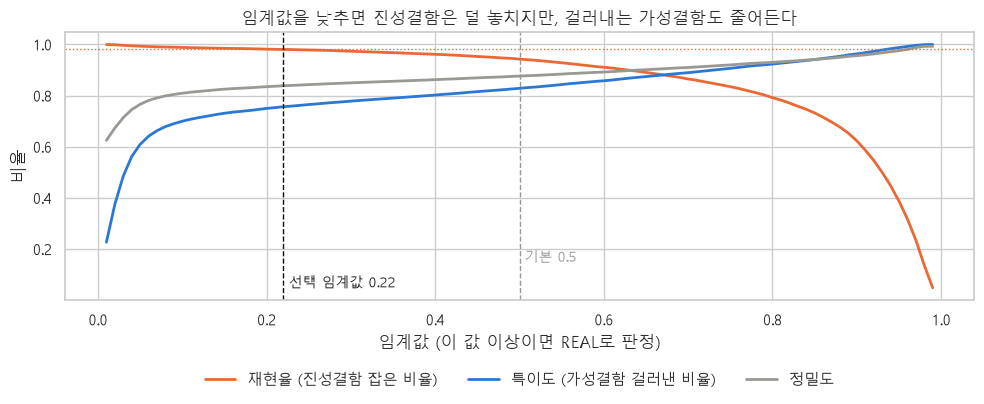

선택 임계값 THR = 0.22


,재현율,정밀도,특이도
임계값,,,
0.2200,0.9801,0.8381,0.7562
0.5000,0.9423,0.8759,0.8281


In [22]:
oof = cross_val_predict(best_clf, Xc_tr, yc_tr, groups=g_tr, cv=gkf, method="predict_proba", n_jobs=-1)[:, 1]

thr_grid = np.round(np.arange(0.01, 1.0, 0.01), 2)
thr_tbl = pd.DataFrame([{"임계값": t,
                         "재현율": recall_score(yc_tr, oof >= t),
                         "정밀도": precision_score(yc_tr, oof >= t, zero_division=0),
                         "특이도": recall_score(yc_tr, oof >= t, pos_label=0)} for t in thr_grid])
TARGET_RECALL = 0.98
THR = thr_tbl.loc[thr_tbl["재현율"] >= TARGET_RECALL, "임계값"].max()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(thr_tbl["임계값"], thr_tbl["재현율"], color=C_REAL, lw=2, label="재현율 (진성결함 잡은 비율)")
ax.plot(thr_tbl["임계값"], thr_tbl["특이도"], color=C_FALSE, lw=2, label="특이도 (가성결함 걸러낸 비율)")
ax.plot(thr_tbl["임계값"], thr_tbl["정밀도"], color=C_GRAY, lw=2, label="정밀도")
ax.axhline(TARGET_RECALL, color=C_REAL, ls=":", lw=1)
ax.axvline(THR, color=C_INK, ls="--", lw=1); ax.axvline(0.5, color=C_GRAY, ls="--", lw=1)
ax.text(THR, 0.05, f" 선택 임계값 {THR}", fontsize=10)
ax.text(0.5, 0.15, " 기본 0.5", fontsize=10, color=C_GRAY)
ax.set_xlabel("임계값 (이 값 이상이면 REAL로 판정)"); ax.set_ylabel("비율")
ax.set_title("임계값을 낮추면 진성결함은 덜 놓치지만, 걸러내는 가성결함도 줄어든다")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.38), ncol=3, frameon=False)
plt.tight_layout(); plt.show()
print(f"선택 임계값 THR = {THR}")
display(thr_tbl[thr_tbl["임계값"].isin([THR, 0.5])].set_index("임계값").round(4))

**프롬프트 P23**
```text
[맥락] THR(선택 임계값), yc_te, proba_te['그래디언트부스팅(튜닝)'], clf_report 함수가 있어.
[작업] 선택한 임계값을 테스트 로트에 적용해 0.5와 비교하고, 현장 언어로 번역해줘.
1. 임계값 0.5와 THR 각각의 clf_report 결과를 두 열 표로.
2. THR 기준으로: 테스트 결함 총수, 'FALSE'로 판정되어 리뷰를 건너뛸 결함 수와 비율,
   그중 실제로는 REAL이었던 결함(놓친 진성결함) 수, 리뷰 대상 결함 수를 출력해줘.
[출력] 표 + 현장 요약 4줄.
```

In [23]:
cmp = pd.DataFrame({"임계값 0.5": clf_report(yc_te, p_best, 0.5),
                    f"임계값 {THR}": clf_report(yc_te, p_best, THR)})
display(cmp.round(4))

skip = p_best < THR                            # FALSE로 판정 → 리뷰 생략
n, n_skip = len(yc_te), skip.sum()
missed = (skip & (yc_te.values == 1)).sum()
print(f"테스트 결함 총 {n:,}개")
print(f"· 리뷰 생략(FALSE 판정) : {n_skip:,}개 ({n_skip / n:.1%})  → 리뷰 공수 {n_skip / n:.1%} 절감")
print(f"· 그중 실제 진성결함    : {missed:,}개 (전체 진성결함의 {missed / yc_te.sum():.1%})")
print(f"· 엔지니어 리뷰 대상    : {n - n_skip:,}개")

,임계값 0.5,임계값 0.22
AUC,0.9533,0.9533
PR_AUC,0.9535,0.9535
정확도,0.8982,0.8836
정밀도,0.8748,0.8367
재현율(REAL),0.9519,0.9808
특이도(FALSE),0.8319,0.7636
F1,0.9117,0.9030


테스트 결함 총 11,883개
· 리뷰 생략(FALSE 판정) : 4,187개 (35.2%)  → 리뷰 공수 35.2% 절감
· 그중 실제 진성결함    : 126개 (전체 진성결함의 1.9%)
· 엔지니어 리뷰 대상    : 7,696개


> **결과 해석**
> - 학습 OOF로 정한 임계값 **0.22**를 테스트에 적용하니 **재현율 98.1%** 로 목표(98%)를 테스트에서도 지켰습니다.
> - 대신 특이도가 83.2% → 76.4%로 내려갔습니다. 놓치는 진성결함을 줄이려고 **가성결함을 조금 덜 걸러내는 거래**를 한 것입니다.
> - 현장 언어로는 **"전체 결함의 35%는 리뷰를 건너뛰고, 그 대가로 진성결함의 1.9%(126개)를 놓친다"** 입니다. 이 숫자를 보고 받아들일지는 **비용을 아는 현장이 결정**합니다. 98%를 99%로 올리면 어떻게 되는지는 연습문제 1에서 확인합니다.

**프롬프트 P24**
```text
[맥락] te(테스트 원본 DataFrame: Step_desc, Class 포함), yc_te, p_best(테스트 확률), THR가 있어.
[작업] 오차 분석을 해줘.
1. 공정(Step_desc)별: 결함 수, REAL 비율, AUC, THR 기준 재현율·특이도 표 (STEP_ORDER 순서).
2. 실제 Class별: 결함 수, THR 기준 '틀린 비율(%)' 표 — 결함 수 30개 이상 Class만, 틀린 비율 내림차순.
[출력] 표 2개 + 어떤 공정·Class에서 모델이 약한지 해석.
```

In [24]:
ev = te[["Step_desc", "Class"]].assign(y=yc_te.values, p=p_best, pred=(p_best >= THR).astype(int))
ev["틀림"] = ev["y"] != ev["pred"]

by_step = ev.groupby("Step_desc").apply(lambda g: pd.Series({
    "결함 수": len(g), "REAL 비율": g["y"].mean(), "AUC": roc_auc_score(g["y"], g["p"]),
    "재현율": recall_score(g["y"], g["pred"]), "특이도": recall_score(g["y"], g["pred"], pos_label=0)}))
display(by_step.loc[STEP_ORDER].round(3))

by_class = ev.groupby("Class").agg(결함수=("y", "size"), 실제=("y", "first"), 틀린비율=("틀림", "mean"))
by_class["실제"] = by_class["실제"].map({1: "REAL", 0: "FALSE"})
by_class["틀린비율(%)"] = by_class.pop("틀린비율") * 100
by_class.query("결함수 >= 30").sort_values("틀린비율(%)", ascending=False).round(1)

,결함 수,REAL 비율,AUC,재현율,특이도
Step_desc,,,,,
PC,"1,372.0000",0.2680,0.9920,0.9780,0.9280
RMG,"4,438.0000",0.5030,0.9480,0.9710,0.7460
CBCMP,"6,073.0000",0.6530,0.9340,0.9870,0.7040


,결함수,실제,틀린비율(%)
Class,,,
9,5318,FALSE,23.6000
14,62,REAL,6.5000
10,923,REAL,6.4000
99,956,REAL,3.2000
17,90,REAL,2.2000
28,137,REAL,1.5000
21,2991,REAL,0.8000
56,342,REAL,0.6000
39,593,REAL,0.2000


> **결과 해석**
> - **PC 공정은 AUC 0.992로 거의 완벽**하지만, **CBCMP(0.934)와 RMG(0.948)는 특이도가 70~75%** 로 가성결함을 덜 걸러냅니다. EDA에서 CBCMP의 로트 간 가성비율 편차가 컸던 것(관리도 이탈 32%)과 같은 맥락입니다.
> - Class별로 보면 **틀린 결함의 대부분이 Class 9(가성결함)** 입니다(23.6%). 재현율 98%를 맞추려고 임계값을 낮췄기 때문에 생긴 의도된 오류입니다.
> - 진성결함 중에서는 **Class 14, 10이 6%대로 가장 많이 놓칩니다.** 이 Class들은 가성결함과 신호가 비슷하다는 뜻이므로, 공정별 전용 모델이나 추가 특성을 검토할 후보입니다(연습문제 2).

---
# 6장. 회귀 모델링 — 신호로 결함 크기 추정

> **이 장의 목표**
> - 로그 변환 타깃으로 회귀 모델을 학습하고 원래 단위로 평가한다.
> - 교차검증으로 회귀 모델을 비교·튜닝한다.
> - 예측-실제 그래프와 잔차로 모델의 약점을 찾는다.

**프롬프트 P25**
```text
[맥락] make_prep, FEAT_REG(크기 변수 제외), Xr_tr, yr_tr(log10 SIZE_D), g_tr, gkf, cv_compare 함수가 있어.
[작업]
1. 원래 단위(µm) 평가용 지표 함수 2개를 만들어줘 (입력은 log10 값):
   mae_um(y, p) = MAE(10**y, 10**p),  mdape(y, p) = 중앙값(|10**p − 10**y| / 10**y) × 100
2. SCORING_REG = {'R2': 'r2', 'MAE_um': make_scorer(mae_um, greater_is_better=False),
                  'MdAPE': make_scorer(mdape, greater_is_better=False)}
3. 회귀 모델 6개 Pipeline 딕셔너리 reg_models (함수 reg_pipe(model, scale)):
   'Dummy'(DummyRegressor mean), '선형 회귀'(scale=True), '릿지'(Ridge(alpha=10), scale=True),
   '의사결정나무'(max_depth=10), '랜덤포레스트'(n_estimators=150, min_samples_leaf=3, max_features=0.5, n_jobs=-1),
   '그래디언트부스팅'(HistGradientBoostingRegressor) — 트리는 random_state=RANDOM_STATE
4. cv_compare(reg_models, Xr_tr, yr_tr, g_tr, SCORING_REG, main='R2')로 비교, R2 내림차순.
[출력] 표 (소수점 4자리).
```

In [25]:
def mae_um(y, p):                     # 로그 → 원래 단위(µm) MAE
    return mean_absolute_error(10 ** y, 10 ** p)

def mdape(y, p):                      # 상대오차의 중앙값(%)
    return np.median(np.abs(10 ** p - 10 ** y) / 10 ** y) * 100

SCORING_REG = {"R2": "r2",
               "MAE_um": make_scorer(mae_um, greater_is_better=False),
               "MdAPE": make_scorer(mdape, greater_is_better=False)}

def reg_pipe(model, scale=False, features=FEAT_REG):
    return Pipeline([("prep", make_prep(features, scale)), ("model", model)])

reg_models = {
    "Dummy":         reg_pipe(DummyRegressor(strategy="mean")),
    "선형 회귀":        reg_pipe(LinearRegression(), scale=True),
    "릿지":            reg_pipe(Ridge(alpha=10), scale=True),
    "의사결정나무":     reg_pipe(DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE)),
    "랜덤포레스트":     reg_pipe(RandomForestRegressor(n_estimators=150, min_samples_leaf=3, max_features=0.5,
                                               n_jobs=-1, random_state=RANDOM_STATE)),
    "그래디언트부스팅": reg_pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
}
t0 = time.time()
reg_cv = cv_compare(reg_models, Xr_tr, yr_tr, g_tr, SCORING_REG, main="R2").sort_values("R2", ascending=False)
print(f"교차검증 소요 {time.time() - t0:.0f}초")
reg_cv.round(4)

교차검증 소요 48초


,R2,MAE_um,MdAPE,R2_표준편차,R2_학습,과적합 간격,학습시간(초)
랜덤포레스트,0.8167,0.1569,16.6605,0.0054,0.9444,0.1278,41.0017
그래디언트부스팅,0.8043,0.1607,18.4350,0.0077,0.8422,0.0380,1.3027
의사결정나무,0.7070,0.2003,20.7426,0.0054,0.8043,0.0973,0.9382
릿지,0.4764,0.3365,37.1270,0.0115,0.4849,0.0085,0.1267
선형 회귀,0.4764,0.3367,37.1225,0.0115,0.4849,0.0085,0.1123
Dummy,0.0057,0.2881,51.4614,0.0032,0.0000,-0.0057,0.0515


**프롬프트 P26**
```text
[맥락] reg_cv 표(모델별 R2, MAE_um, MdAPE)가 있어.
[작업] 회귀 모델 비교를 1×3 가로 막대그래프로 그려줘 (R2 / MAE(µm) / MdAPE(%)).
- 각 패널에서 가장 좋은 모델만 주황(C_REAL), 나머지 회색. (R2는 클수록, 나머지는 작을수록 좋음)
- 막대 끝에 값 표시, Dummy의 값은 회색 점선 세로선으로 표시(기준선).
- 패널 제목에 '↑ 클수록 좋음' / '↓ 작을수록 좋음'.
```

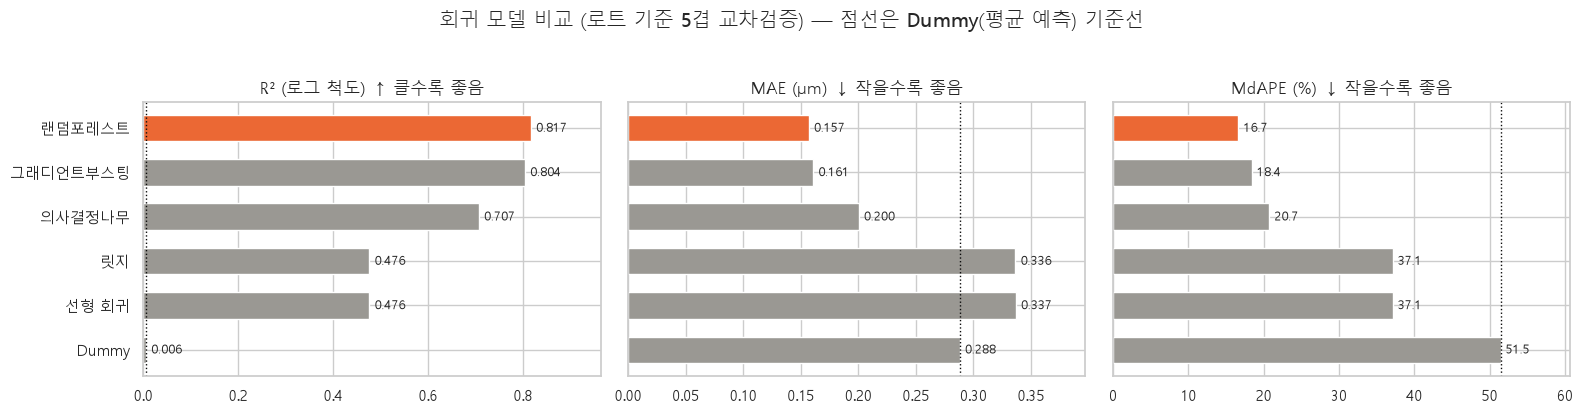

In [26]:
s = reg_cv.sort_values("R2")
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, col, good, title, fmt in [(axes[0], "R2", "max", "R² (로그 척도) ↑ 클수록 좋음", "{:.3f}"),
                                  (axes[1], "MAE_um", "min", "MAE (µm) ↓ 작을수록 좋음", "{:.3f}"),
                                  (axes[2], "MdAPE", "min", "MdAPE (%) ↓ 작을수록 좋음", "{:.1f}")]:
    best = s[col].idxmax() if good == "max" else s[col].idxmin()
    ax.barh(s.index, s[col], color=[C_REAL if n == best else C_GRAY for n in s.index], height=0.6)
    ax.axvline(s.loc["Dummy", col], color=C_INK, ls=":", lw=1)
    for i, v in enumerate(s[col]):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=9)
    ax.set_title(title); ax.margins(x=0.18)
plt.suptitle("회귀 모델 비교 (로트 기준 5겹 교차검증) — 점선은 Dummy(평균 예측) 기준선", y=1.03)
plt.tight_layout(); plt.show()

> **결과 해석**
> - 트리 앙상블(**RF R² 0.817, HGB 0.804**)이 선형 모델(0.476)보다 훨씬 낫습니다. 신호와 크기의 관계도 직선이 아닙니다.
> - **선형 회귀는 MAE가 Dummy보다 나쁩니다(0.337 > 0.288).** 로그 척도에서는 Dummy보다 낫지만(R² 0.48), µm로 되돌리면 큰 결함에서 예측이 크게 빗나갑니다. **지표를 여러 개 보는 이유**입니다.
> - RF는 과적합 간격(0.128)이 크고 학습에 약 37초가 걸립니다. HGB는 간격 0.038에 약 3초입니다. 성능 차이가 작으므로 **HGB를 튜닝**합니다.

**프롬프트 P27**
```text
[맥락] reg_pipe, Xr_tr, yr_tr, g_tr, gkf가 있어.
[작업] HistGradientBoostingRegressor를 RandomizedSearchCV로 튜닝해줘.
- 탐색 공간: learning_rate [0.03, 0.05, 0.1, 0.2], max_leaf_nodes [15, 31, 63, 127],
  min_samples_leaf [10, 20, 50, 100], l2_regularization [0, 0.1, 1.0], max_iter [200, 400, 800]
- n_iter=15, cv=gkf, scoring='r2', random_state=RANDOM_STATE, n_jobs=-1, groups=g_tr
[출력] 최적 파라미터, 최적 CV R², 기본 모델 대비 차이.
```

In [27]:
param_reg = {k: v for k, v in param_clf.items()}          # 분류와 같은 탐색 공간
search_reg = RandomizedSearchCV(reg_pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
                                param_reg, n_iter=15, cv=gkf, scoring="r2",
                                random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.time()
search_reg.fit(Xr_tr, yr_tr, groups=g_tr)
print(f"튜닝 소요 {time.time() - t0:.0f}초")
print("최적 파라미터 :", {k.replace("model__", ""): v for k, v in search_reg.best_params_.items()})
print(f"최적 CV R²   : {search_reg.best_score_:.4f}  (기본값 {reg_cv.loc['그래디언트부스팅', 'R2']:.4f}, "
      f"차이 {search_reg.best_score_ - reg_cv.loc['그래디언트부스팅', 'R2']:+.4f})")

튜닝 소요 91초
최적 파라미터 : {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 800, 'learning_rate': 0.05, 'l2_regularization': 0.1}
최적 CV R²   : 0.8233  (기본값 0.8043, 차이 +0.0190)


**프롬프트 P28**
```text
[맥락] search_reg.best_estimator_, reg_models, Xr_tr, yr_tr, Xr_te, yr_te, mae_um, mdape가 있어.
[작업] 테스트 로트에서 최종 평가해줘.
1. best_reg = search_reg.best_estimator_, 비교용 '랜덤포레스트', '선형 회귀', 'Dummy'는 학습 데이터로 fit.
2. 함수 reg_report(y, p): R²(로그), MAE(µm), RMSE(µm), MdAPE(%) — µm 지표는 10**로 되돌려 계산.
3. 4개 모델의 테스트 예측을 pred_te 딕셔너리에 저장하고, 지표 표를 R² 내림차순으로.
[출력] 표 + 'Dummy 대비 MAE xx% 감소' 한 줄.
```

In [28]:
def reg_report(y, p):
    return {"R²(로그)": r2_score(y, p), "MAE(µm)": mae_um(y, p),
            "RMSE(µm)": root_mean_squared_error(10 ** y, 10 ** p), "MdAPE(%)": mdape(y, p)}

best_reg = search_reg.best_estimator_
final_reg = {"그래디언트부스팅(튜닝)": best_reg}
for name in ["랜덤포레스트", "선형 회귀", "Dummy"]:
    final_reg[name] = reg_models[name].fit(Xr_tr, yr_tr)

pred_te = {name: m.predict(Xr_te) for name, m in final_reg.items()}
reg_test = pd.DataFrame({n: reg_report(yr_te, p) for n, p in pred_te.items()}).T.sort_values("R²(로그)", ascending=False)
display(reg_test.round(4))
cut = 1 - reg_test.loc["그래디언트부스팅(튜닝)", "MAE(µm)"] / reg_test.loc["Dummy", "MAE(µm)"]
print(f"Dummy 대비 MAE {cut:.0%} 감소")

,R²(로그),MAE(µm),RMSE(µm),MdAPE(%)
그래디언트부스팅(튜닝),0.8219,0.1240,0.8793,17.2093
랜덤포레스트,0.8159,0.1226,0.9116,16.9599
선형 회귀,0.4810,0.3016,3.0730,39.4455
Dummy,-0.0030,0.2530,1.1875,54.7795


Dummy 대비 MAE 51% 감소


> **결과 해석**
> - 튜닝한 HGB가 **R² 0.822로 가장 높고**, MAE 0.124µm·MdAPE 17.2%는 랜덤포레스트(0.123µm, 17.0%)와 사실상 같습니다. Dummy보다 **MAE가 51% 줄었습니다.** 성능이 같으므로 더 가볍고 빠른 HGB를 씁니다.
> - MdAPE 17%는 "**결함 절반은 실제 크기의 ±17% 안으로 맞힌다**"는 뜻입니다.
> - RMSE(0.88µm)가 MAE(0.12µm)의 7배인 것은 **드문 대형 결함에서 큰 오차**가 난다는 신호입니다. → 아래 크기 등급별 분석에서 확인합니다.

**프롬프트 P29**
```text
[맥락] yr_te(실제 log10 크기), pred_te['그래디언트부스팅(튜닝)']가 있어.
[작업] 회귀 진단 그래프 1×2를 그려줘.
1. 왼쪽: 실제 SIZE_D vs 예측 SIZE_D (µm, 둘 다 로그 축) hexbin(gridsize=60, cmap='Blues', bins='log'),
   y=x 대각선(검은 점선), ±2배 오차 띠(회색 점선 y=2x, y=x/2). 제목에 '±2배 안에 든 비율 xx%'.
2. 오른쪽: 잔차(실제 log − 예측 log) vs 예측 log 산점도(점 작게, 투명도 0.15),
   y=0 선, 예측값 구간(20개 분위)별 잔차 중앙값을 주황 선으로.
[조건] 로그 축은 plain_log로 일반 숫자 눈금.
```

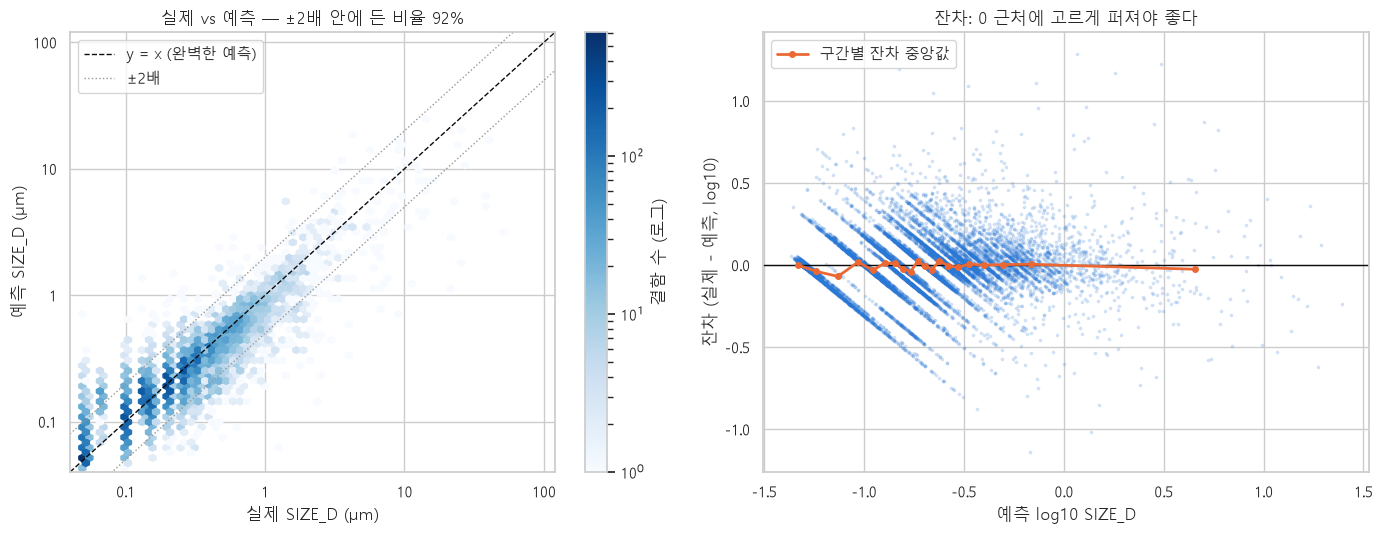

In [29]:
yt, yp = yr_te.values, pred_te["그래디언트부스팅(튜닝)"]
within2 = (np.abs(yp - yt) <= np.log10(2)).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
hb = axes[0].hexbin(10 ** yt, 10 ** yp, gridsize=60, cmap="Blues", bins="log", xscale="log", yscale="log", mincnt=1)
lim = [0.04, 120]
axes[0].plot(lim, lim, "--", color=C_INK, lw=1, label="y = x (완벽한 예측)")
axes[0].plot(lim, [2 * v for v in lim], ":", color=C_GRAY, lw=1, label="±2배")
axes[0].plot(lim, [v / 2 for v in lim], ":", color=C_GRAY, lw=1)
axes[0].set_xlim(lim); axes[0].set_ylim(lim); plain_log(axes[0], "both")
axes[0].set_xlabel("실제 SIZE_D (µm)"); axes[0].set_ylabel("예측 SIZE_D (µm)")
axes[0].set_title(f"실제 vs 예측 — ±2배 안에 든 비율 {within2:.0%}"); axes[0].legend(loc="upper left")
plt.colorbar(hb, ax=axes[0], label="결함 수 (로그)")

resid = yt - yp
axes[1].scatter(yp, resid, s=3, alpha=0.15, color=C_FALSE)
axes[1].axhline(0, color=C_INK, lw=1)
bins = pd.qcut(yp, 20)
med = pd.Series(resid).groupby(bins, observed=True).median()
axes[1].plot([b.mid for b in med.index], med.values, "-o", color=C_REAL, lw=2, ms=4, label="구간별 잔차 중앙값")
axes[1].set_xlabel("예측 log10 SIZE_D"); axes[1].set_ylabel("잔차 (실제 - 예측, log10)")
axes[1].set_title("잔차: 0 근처에 고르게 퍼져야 좋다"); axes[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

> **결과 해석**
> - 왼쪽: 점들이 대각선 주위에 모여 있고 **92%가 실제의 ±2배 안**에 듭니다. 실제 SIZE_D가 0.05, 0.1, 0.15처럼 **일정 간격의 값으로만 기록**되어 세로 줄무늬가 생깁니다(측정 해상도).
> - 오른쪽: 구간별 잔차 중앙값(주황)이 0 근처로 평평하여 **전체적인 편향은 없습니다.** 비스듬한 줄무늬도 같은 측정 해상도 때문입니다.
> - 다만 10µm 이상 대형 결함은 대각선 아래, 즉 **실제보다 작게 예측**하는 경향이 있습니다(데이터가 적은 구간).

**프롬프트 P30**
```text
[맥락] te(테스트 원본, Step_desc·SIZE_D 포함), yr_te, pred_te['그래디언트부스팅(튜닝)']가 있어.
[작업] 회귀 오차를 두 가지로 쪼개 분석해줘.
1. 실제 크기 등급별: SIZE_D를 [0, 0.1), [0.1, 0.2), [0.2, 0.5), [0.5, 1), [1, ∞) µm로 나누고
   등급별 결함 수, MAE(µm), MdAPE(%), 평균 잔차(log, +면 과소예측) 표.
2. 크기 등급을 '소(<0.2) / 중(0.2~1) / 대(≥1)' 3단계로 나눠, 실제 등급과 예측 등급의
   교차표(행 기준 %)를 만들어 등급 일치율을 계산해줘.
[출력] 표 2개 + 일치율 한 줄.
```

In [30]:
ev_r = pd.DataFrame({"실제": 10 ** yr_te.values, "예측": 10 ** pred_te["그래디언트부스팅(튜닝)"],
                     "Step_desc": te["Step_desc"].values})
ev_r["잔차log"] = np.log10(ev_r["실제"]) - np.log10(ev_r["예측"])
ev_r["크기구간"] = pd.cut(ev_r["실제"], [0, 0.1, 0.2, 0.5, 1, np.inf], right=False,
                       labels=["<0.1", "0.1~0.2", "0.2~0.5", "0.5~1", "≥1"])
display(ev_r.groupby("크기구간", observed=True).apply(lambda g: pd.Series({
    "결함 수": len(g), "MAE(µm)": mean_absolute_error(g["실제"], g["예측"]),
    "MdAPE(%)": np.median(np.abs(g["예측"] - g["실제"]) / g["실제"]) * 100,
    "평균 잔차(log)": g["잔차log"].mean()})).round(3))

grade = lambda v: pd.cut(v, [0, 0.2, 1, np.inf], right=False, labels=["소(<0.2)", "중(0.2~1)", "대(≥1)"])
ct = pd.crosstab(grade(ev_r["실제"]), grade(ev_r["예측"]), rownames=["실제 등급"], colnames=["예측 등급"],
                 normalize="index") * 100
display(ct.round(1))
print(f"크기 등급 일치율 : {(grade(ev_r['실제']) == grade(ev_r['예측'])).mean():.1%}")

,결함 수,MAE(µm),MdAPE(%),평균 잔차(log)
크기구간,,,,
<0.1,"3,039.0000",0.0260,17.4200,-0.0920
0.1~0.2,"3,685.0000",0.0380,17.0010,-0.0210
0.2~0.5,"3,517.0000",0.0740,15.5330,0.0510
0.5~1,"1,130.0000",0.1780,19.5420,0.0760
≥1,512.0000,1.5470,33.0370,0.1520


예측 등급,소(<0.2),중(0.2~1),대(≥1)
실제 등급,,,
소(<0.2),83.7000,16.3000,0.0000
중(0.2~1),12.2000,86.1000,1.6000
대(≥1),0.4000,30.9000,68.8000


크기 등급 일치율 : 84.0%


> **결과 해석**
> - 평균 잔차가 작은 결함(<0.1µm)에서는 **−0.09(크게 예측)**, 대형 결함(≥1µm)에서는 **+0.15(작게 예측)** 입니다. 모델이 양 끝을 가운데로 끌어당기는 **평균 회귀** 현상입니다.
> - 대형 결함의 MdAPE는 33%로 다른 구간(15~20%)의 약 2배입니다. 대형 결함은 512개(4%)뿐이라 배울 데이터가 적습니다.
> - 소/중/대 **등급 일치율은 84%** 입니다. 그러나 **대형 결함의 31%를 '중'으로 낮춰** 봅니다. "큰 결함 우선 리뷰"에 쓰려면 대형 판정 기준을 낮추거나 대형 결함 전용 분류 모델을 추가해야 합니다.

---
# 7장. 변수 중요도 — 모델은 무엇을 보고 판단했나?

> **이 장의 목표**
> - 변수 중요도의 종류(계수·불순도·순열·그룹·PDP)와 장단점을 안다.
> - 여러 방법의 결과를 비교해 믿을 만한 결론을 낸다.
> - 중요도 ≠ 인과관계임을 이해한다.

## 7-1. 변수 중요도의 종류

| 방법 | 원리 | 장점 | 주의 |
|---|---|---|---|
| **표준화 계수** (선형 모델) | 표준화된 특성의 계수 크기·부호 | 방향(+/−)까지 보임 | 비선형 관계는 못 잡음 |
| **불순도 감소 (MDI)** (트리) | 분할로 불순도를 얼마나 줄였나 | 학습 중 공짜로 계산 | 학습 데이터 기준, **값 종류가 많은 변수를 과대평가** |
| **순열 중요도** (모든 모델) | 한 변수를 무작위로 섞었을 때 성능이 얼마나 떨어지나 | 모델 무관, 테스트 데이터로 계산 가능 | **상관 높은 변수끼리 중요도를 나눠 가짐** |
| **그룹 순열 중요도** | 관련 변수 묶음을 한꺼번에 섞음 | 상관 문제 완화 | 그룹 정의가 필요 |
| **부분 의존도 (PDP)** | 한 변수만 바꿀 때 평균 예측이 어떻게 변하나 | **방향과 모양**을 보여줌 | 변수 간 상호작용은 평균에 묻힘 |

```
 순열 중요도의 원리
   원래 테스트 데이터 → AUC 0.95
   INTENSITY 열만 무작위로 섞음 → AUC 0.80   ⇒ 중요도 = 0.95 − 0.80 = 0.15
   ANGLE 열만 섞음            → AUC 0.95   ⇒ 중요도 ≈ 0      (안 쓰는 변수)
```

> **중요도 ≠ 원인.** "모델이 예측에 많이 쓴 변수"일 뿐, 그 변수를 바꾸면 결함이 바뀐다는 뜻이 아닙니다.

**프롬프트 P31**
```text
[맥락] final_clf['로지스틱 회귀'](학습된 Pipeline, prep에 StandardScaler + OneHot)가 있어.
[작업] 로지스틱 회귀의 표준화 계수를 변수 중요도로 보여줘.
1. named_steps['prep'].get_feature_names_out()과 named_steps['model'].coef_[0]으로 Series coef를 만들어줘.
2. 절댓값 기준 상위 15개를 가로 막대로: 양수(REAL 쪽)=주황 C_REAL, 음수(FALSE 쪽)=파랑 C_FALSE.
3. 오즈비 exp(계수)도 계산해 '1 표준편차 증가 시 REAL 오즈 x배' 표로 상위 5개.
[조건] 0에 세로선, 제목에 해석 방향을 써줘.
```

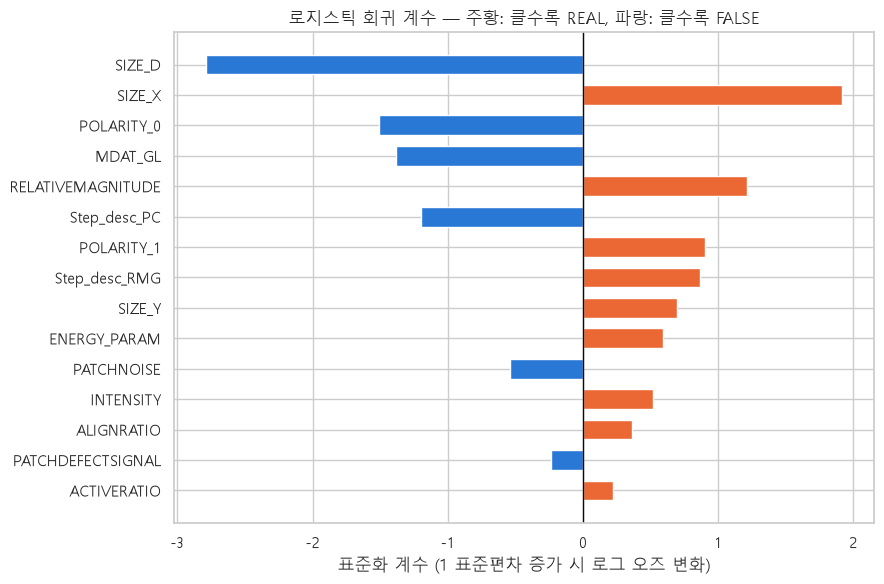

,계수,오즈비 exp(계수)
SIZE_D,-2.7880,0.0620
SIZE_X,1.9180,6.8080
POLARITY_0,-1.5100,0.2210
MDAT_GL,-1.3860,0.2500
RELATIVEMAGNITUDE,1.2120,3.3600


In [31]:
lr = final_clf["로지스틱 회귀"]
coef = pd.Series(lr.named_steps["model"].coef_[0], index=lr.named_steps["prep"].get_feature_names_out())
top = coef.reindex(coef.abs().sort_values().index[-15:])

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=[C_REAL if v > 0 else C_FALSE for v in top.values], height=0.65)
ax.axvline(0, color=C_INK, lw=1)
ax.set_xlabel("표준화 계수 (1 표준편차 증가 시 로그 오즈 변화)")
ax.set_title("로지스틱 회귀 계수 — 주황: 클수록 REAL, 파랑: 클수록 FALSE")
plt.tight_layout(); plt.show()

odds = coef.reindex(coef.abs().sort_values(ascending=False).index[:5]).to_frame("계수")
odds["오즈비 exp(계수)"] = np.exp(odds["계수"])
odds.round(3)

**프롬프트 P32**
```text
[맥락] final_clf['랜덤포레스트'](학습된 Pipeline), CAT_COLS가 있어.
[작업] 랜덤포레스트의 불순도 기반 중요도(feature_importances_)를 원래 변수 단위로 보여줘.
1. 원-핫 열(예: Step_desc_PC, POLARITY_1)은 원래 변수(Step_desc, POLARITY)로 합산해줘 → Series mdi.
2. 내림차순 가로 막대(단일 색 C_GRAY, 상위 3개만 C_REAL), 막대 끝에 값(소수 3자리).
```

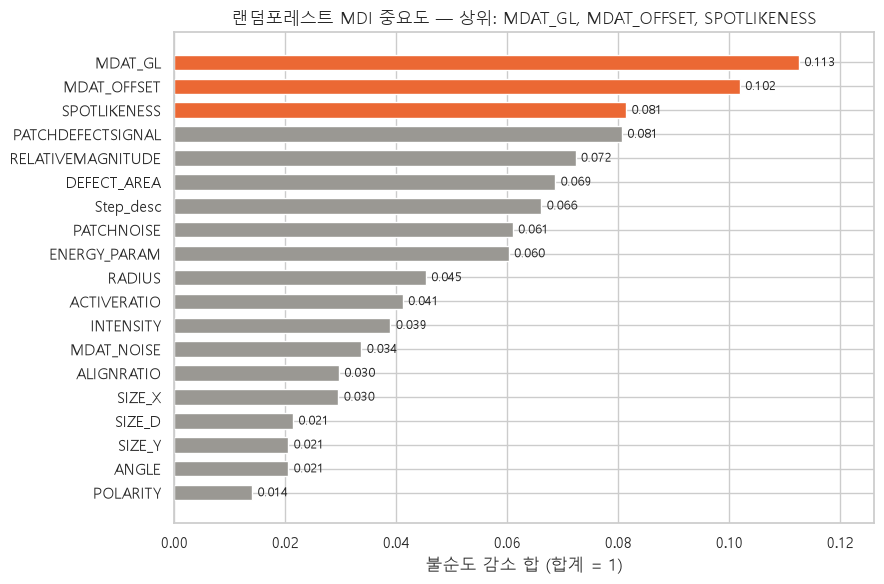

In [32]:
rf = final_clf["랜덤포레스트"]
raw = pd.Series(rf.named_steps["model"].feature_importances_, index=rf.named_steps["prep"].get_feature_names_out())
to_raw = lambda n: next((c for c in CAT_COLS if n.startswith(c + "_")), n)   # 원-핫 열 → 원래 변수
mdi = raw.groupby(to_raw).sum().sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(mdi.index, mdi.values, color=[C_REAL if i >= len(mdi) - 3 else C_GRAY for i in range(len(mdi))], height=0.65)
for i, v in enumerate(mdi.values):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)
ax.set_xlabel("불순도 감소 합 (합계 = 1)"); ax.margins(x=0.12)
ax.set_title(f"랜덤포레스트 MDI 중요도 — 상위: {', '.join(mdi.index[::-1][:3])}")
plt.tight_layout(); plt.show()

**프롬프트 P33**
```text
[맥락] best_clf(튜닝된 HGB Pipeline), Xc_te, yc_te가 있어.
[작업] 테스트 데이터로 순열 중요도를 계산해줘.
- permutation_importance(best_clf, Xc_te, yc_te, scoring='roc_auc', n_repeats=10,
  random_state=RANDOM_STATE, n_jobs=-1) — Pipeline에 원본 열을 넣으므로 결과도 원래 변수 단위.
- 결과를 DataFrame perm_clf(평균, 표준편차)로, 평균 내림차순.
- 가로 막대 + 오차막대(표준편차), 상위 3개 C_REAL, 나머지 C_GRAY, 0에 세로선.
[출력] 그래프 + '상위 5개 변수가 전체 중요도 합의 xx%' 한 줄.
```

계산 34초


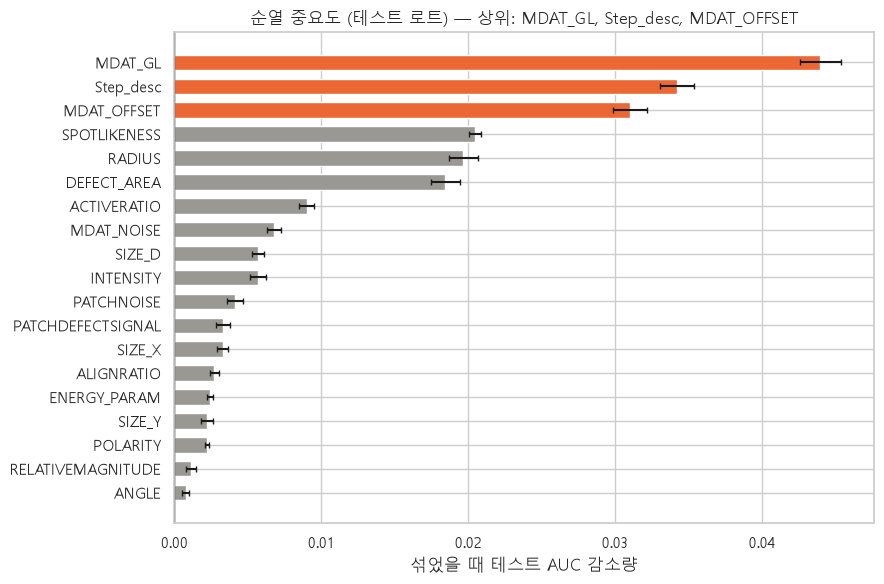

상위 5개 변수가 전체 중요도 합의 69%


In [33]:
t0 = time.time()
pi = permutation_importance(best_clf, Xc_te, yc_te, scoring="roc_auc", n_repeats=10,
                            random_state=RANDOM_STATE, n_jobs=-1)
perm_clf = pd.DataFrame({"평균": pi.importances_mean, "표준편차": pi.importances_std},
                        index=Xc_te.columns).sort_values("평균")
print(f"계산 {time.time() - t0:.0f}초")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(perm_clf.index, perm_clf["평균"], xerr=perm_clf["표준편차"], capsize=2, height=0.65,
        color=[C_REAL if i >= len(perm_clf) - 3 else C_GRAY for i in range(len(perm_clf))])
ax.axvline(0, color=C_INK, lw=1)
ax.set_xlabel("섞었을 때 테스트 AUC 감소량")
ax.set_title(f"순열 중요도 (테스트 로트) — 상위: {', '.join(perm_clf.index[::-1][:3])}")
plt.tight_layout(); plt.show()
share = perm_clf["평균"].clip(lower=0)
print(f"상위 5개 변수가 전체 중요도 합의 {share.nlargest(5).sum() / share.sum():.0%}")

**프롬프트 P34**
```text
[맥락] coef(로지스틱 표준화 계수, 원-핫 열 단위), mdi(RF 불순도, 원래 변수 단위),
       perm_clf(HGB 순열 중요도, 원래 변수 단위), to_raw 함수가 있어.
[작업] 세 방법의 변수 순위를 한 표로 비교해줘.
1. 로지스틱 계수는 |계수|를 to_raw로 원래 변수 단위로 합산.
2. 각 방법의 순위(1=가장 중요)를 열로, 세 순위의 평균 순위로 정렬.
3. 세 방법 순위 사이의 스피어만 상관계수 행렬도 출력해줘.
[출력] 순위표(상위 10개) + 상관 행렬 + 해석.
```

In [34]:
coef_raw = coef.abs().groupby(to_raw).sum()
imp = pd.DataFrame({"로지스틱 |계수|": coef_raw, "RF 불순도": mdi, "HGB 순열": perm_clf["평균"]})
rank = imp.rank(ascending=False).astype(int)
rank["평균 순위"] = rank.mean(axis=1)
display(rank.sort_values("평균 순위").head(10))
print("방법 간 순위 일치도 (스피어만 ρ)")
imp.corr(method="spearman").round(2)

,로지스틱 |계수|,RF 불순도,HGB 순열,평균 순위
MDAT_GL,5,1,1,2.3333
Step_desc,3,7,2,4.0000
MDAT_OFFSET,16,2,3,7.0000
SPOTLIKENESS,15,3,4,7.3333
SIZE_D,1,16,9,8.6667
PATCHNOISE,9,8,11,9.3333
PATCHDEFECTSIGNAL,12,4,12,9.3333
DEFECT_AREA,17,6,6,9.6667
RELATIVEMAGNITUDE,6,5,18,9.6667
ACTIVERATIO,13,11,7,10.3333


방법 간 순위 일치도 (스피어만 ρ)


,로지스틱 |계수|,RF 불순도,HGB 순열
로지스틱 |계수|,1.0000,-0.2100,-0.1600
RF 불순도,-0.2100,1.0000,0.6200
HGB 순열,-0.1600,0.6200,1.0000


> **결과 해석**
> - **RF 불순도와 HGB 순열 중요도는 순위가 비슷하고(ρ = 0.62)**, 두 방법 모두 **MDAT_GL**을 1위로 꼽습니다.
> - 로지스틱 계수는 다른 두 방법과 순위가 **거의 반대(ρ ≈ −0.2)** 입니다. 로지스틱은 **SIZE_D(−2.79)와 SIZE_X(+1.92)에 부호가 반대인 큰 계수**를 주었습니다. 두 변수의 상관이 0.88로 높아 계수가 서로 상쇄되는 **다중공선성** 현상입니다. 계수 크기를 그대로 중요도로 읽으면 안 됩니다.
> - 결론: **한 방법만 믿지 말고, 여러 방법에서 공통으로 상위에 있는 변수**(MDAT_GL, Step_desc, MDAT_OFFSET, SPOTLIKENESS)를 핵심 변수로 봅니다.

**프롬프트 P35**
```text
[맥락] best_clf, Xc_te, yc_te가 있어. 크기 변수(SIZE_X, SIZE_Y, DEFECT_AREA, SIZE_D)는 서로 상관이 매우 높아
       순열 중요도를 나눠 가질 수 있어.
[작업] 변수 그룹 단위 순열 중요도를 직접 구현해줘.
- 그룹: 크기=SIZE_COLS, 신호=SIG_COLS+['POLARITY'], 형상=SHAPE_COLS, 위치=POS_COLS, 공정=['Step_desc']
- 함수 group_perm(model, X, y, groups, n_repeats=5): 같은 무작위 순서(rng.permutation)로
  그룹의 열을 한꺼번에 섞고 AUC 감소량의 평균·표준편차를 반환. rng = np.random.default_rng(RANDOM_STATE).
- 비교용으로 '개별 순열 중요도 합'(perm_clf에서 그룹 열의 합)도 같은 표에.
[출력] 표 + 가로 막대 그래프(그룹 중요도, 오차막대) + 해석.
```

,그룹 중요도,표준편차,개별 순열 합
신호,0.2132,0.0035,0.0965
형상,0.0518,0.0018,0.0363
공정,0.0352,0.0013,0.0342
크기,0.0302,0.0010,0.0297
위치,0.0212,0.0009,0.0205


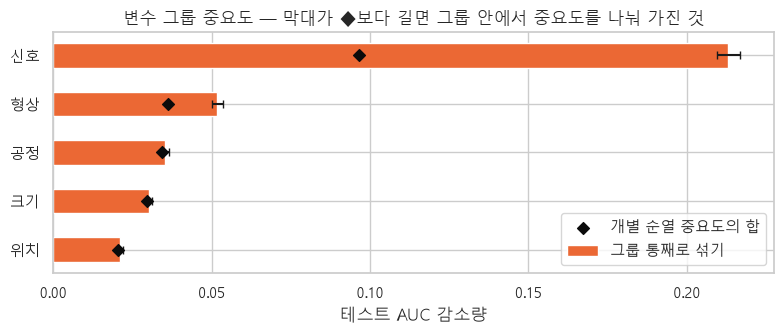

In [35]:
FEAT_GROUPS = {"크기": SIZE_COLS, "신호": SIG_COLS + ["POLARITY"], "형상": SHAPE_COLS,
               "위치": POS_COLS, "공정": ["Step_desc"]}

def group_perm(model, X, y, groups, n_repeats=5):
    rng = np.random.default_rng(RANDOM_STATE)
    base = roc_auc_score(y, model.predict_proba(X)[:, 1])
    out = {}
    for g, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(X))]     # 그룹 열을 같은 순서로 함께 섞기
            drops.append(base - roc_auc_score(y, model.predict_proba(Xp)[:, 1]))
        out[g] = {"그룹 중요도": np.mean(drops), "표준편차": np.std(drops)}
    return pd.DataFrame(out).T

gp = group_perm(best_clf, Xc_te, yc_te, FEAT_GROUPS)
gp["개별 순열 합"] = [perm_clf.loc[c, "평균"].sum() for c in FEAT_GROUPS.values()]
gp = gp.sort_values("그룹 중요도")
display(gp[::-1].round(4))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(gp.index, gp["그룹 중요도"], xerr=gp["표준편차"], color=C_REAL, height=0.5, capsize=3, label="그룹 통째로 섞기")
ax.scatter(gp["개별 순열 합"], gp.index, marker="D", color=C_INK, zorder=3, label="개별 순열 중요도의 합")
ax.set_xlabel("테스트 AUC 감소량"); ax.legend(loc="lower right")
ax.set_title("변수 그룹 중요도 — 막대가 ◆보다 길면 그룹 안에서 중요도를 나눠 가진 것")
plt.tight_layout(); plt.show()

> **결과 해석**
> - 그룹으로 보면 **신호 그룹이 압도적(AUC −0.213)** 이고 형상(−0.052), 공정(−0.035), 크기(−0.030), 위치(−0.021)가 뒤를 잇습니다.
> - 신호 그룹은 **개별 순열 합(0.097)의 2배 이상**입니다. 신호 변수끼리 정보가 겹쳐 하나를 섞어도 다른 변수가 대신하지만, **한꺼번에 없애면 큰 손실**이 납니다. 개별 순열 중요도가 상관 높은 변수를 과소평가하는 예입니다.
> - 크기 그룹은 막대와 ◆가 거의 같습니다. 크기 정보는 판정에서 **보조 역할**에 그칩니다.

**프롬프트 P36**
```text
[맥락] best_clf, Xc_te, perm_clf(순열 중요도, 내림차순 정렬 가능)가 있어.
[작업] 순열 중요도 상위 3개 수치형 변수의 부분 의존도(PDP)를 그려줘.
- 범주형(Step_desc, POLARITY)은 제외하고 상위 3개 선택.
- PartialDependenceDisplay.from_estimator(best_clf, Xc_te 중 무작위 3000행(random_state 고정), features,
  kind='both'(평균 PDP + 개별 ICE), subsample=80, random_state=RANDOM_STATE, grid_resolution=40,
  percentiles=(0.02, 0.98))
- 평균선은 주황 굵게, ICE 선은 회색 얇게. y축 = 'REAL일 확률'.
[출력] 1×3 그래프 + 변수별로 '값이 커질수록 REAL 확률이 ...' 해석.
```

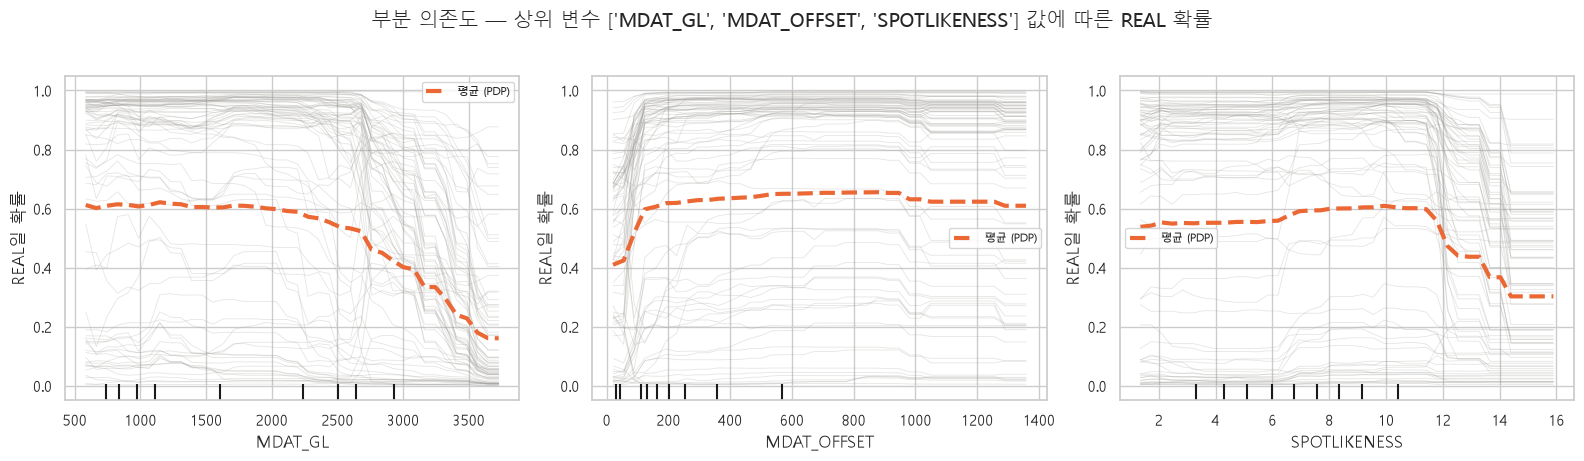

In [36]:
top_num = [c for c in perm_clf.sort_values("평균", ascending=False).index if c not in CAT_COLS][:3]
X_pdp = Xc_te.sample(3000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
PartialDependenceDisplay.from_estimator(
    best_clf, X_pdp, top_num, kind="both", subsample=80, random_state=RANDOM_STATE,
    grid_resolution=40, percentiles=(0.02, 0.98), ax=axes,
    ice_lines_kw={"color": C_GRAY, "alpha": 0.25, "lw": 0.6},
    pd_line_kw={"color": C_REAL, "lw": 3, "label": "평균 (PDP)"})
for ax in axes:
    ax.set_ylabel("REAL일 확률"); ax.legend(loc="best", fontsize=8)
plt.suptitle(f"부분 의존도 — 상위 변수 {top_num} 값에 따른 REAL 확률", y=1.02)
plt.tight_layout(); plt.show()

> **결과 해석**
> - **MDAT_GL** : 약 2,500을 넘으면 REAL 확률이 0.6 → 0.2 아래로 급격히 떨어집니다. 배경 밝기가 높은 곳의 검출은 가성결함일 가능성이 큽니다.
> - **MDAT_OFFSET** : 약 100 미만에서 REAL 확률이 낮고(0.4), 그 이상에서는 거의 평평합니다(0.6). **문턱(threshold) 형태의 관계**입니다.
> - **SPOTLIKENESS** : 약 12를 넘으면 REAL 확률이 0.6 → 0.3으로 떨어집니다. 점(spot)처럼 생긴 검출일수록 노이즈일 가능성이 큽니다.
> - 회색 ICE 선이 위(≈1)와 아래(≈0) 두 무리로 갈리는 것은 **다른 변수와의 상호작용**이 강하다는 뜻입니다. 평균선만 보면 이 차이가 가려집니다.
> - 이것은 **모델이 학습한 패턴**입니다. 변수를 바꾸면 결함이 바뀐다는 인과관계가 아닙니다.

**프롬프트 P37**
```text
[맥락] mdi(RF 불순도 중요도, 학습 데이터 기반 원래 변수 단위), clf_pipe, FEAT_CLF, Xc_tr, yc_tr, g_tr, gkf가 있어.
[작업] '변수를 몇 개만 써도 충분한가?' 실험을 해줘.
- 순위는 테스트로 계산한 순열 중요도가 아니라 **학습 데이터 기반 mdi 순위**를 사용해 (테스트 정보 누수 방지).
- k = 1, 2, 3, 5, 8, 12, 전체 개수에 대해 상위 k개 변수만으로
  clf_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE), features=상위k) 교차검증 AUC 평균·표준편차.
- 꺾은선 그래프(x=k, y=AUC, 오차막대), 전체 변수 AUC의 99% 수준에 수평 점선.
[출력] 표 + 그래프 + 'k개면 전체 성능의 99%' 한 줄.
```

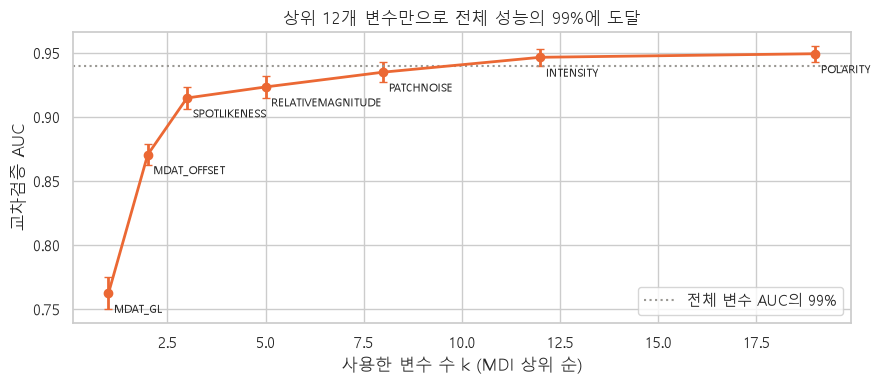

,k,AUC 평균,AUC 표준편차,추가된 변수
0,1,0.7623,0.0125,MDAT_GL
1,2,0.8705,0.0083,MDAT_OFFSET
2,3,0.9148,0.0083,SPOTLIKENESS
3,5,0.9234,0.0084,RELATIVEMAGNITUDE
4,8,0.9350,0.0079,PATCHNOISE
5,12,0.9466,0.0067,INTENSITY
6,19,0.9493,0.0064,POLARITY


In [37]:
order = mdi.sort_values(ascending=False).index.tolist()
ks = [1, 2, 3, 5, 8, 12, len(order)]
rows = []
for k in ks:
    feats = order[:k]
    sc = cross_validate(clf_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE), features=feats),
                        Xc_tr[feats], yc_tr, cv=gkf, groups=g_tr, scoring="roc_auc", n_jobs=-1)["test_score"]
    rows.append({"k": k, "AUC 평균": sc.mean(), "AUC 표준편차": sc.std(), "추가된 변수": order[k - 1]})
topk = pd.DataFrame(rows)
full = topk["AUC 평균"].iloc[-1]
k99 = topk.loc[topk["AUC 평균"] >= 0.99 * full, "k"].min()

fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(topk["k"], topk["AUC 평균"], yerr=topk["AUC 표준편차"], fmt="-o", color=C_REAL, lw=2, capsize=3)
ax.axhline(0.99 * full, color=C_GRAY, ls=":", label="전체 변수 AUC의 99%")
for _, r in topk.iterrows():
    ax.annotate(r["추가된 변수"], (r["k"], r["AUC 평균"]), xytext=(4, -14), textcoords="offset points", fontsize=8)
ax.set_xlabel("사용한 변수 수 k (MDI 상위 순)"); ax.set_ylabel("교차검증 AUC")
ax.set_title(f"상위 {k99}개 변수만으로 전체 성능의 99%에 도달"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
topk.round(4)

> **결과 해석**
> - **MDAT_GL 하나만으로 AUC 0.76**, 3개(+MDAT_OFFSET, SPOTLIKENESS)로 **0.915** 입니다. 변수 3개가 성능의 대부분을 만듭니다.
> - 99% 기준(AUC 0.940)은 12개에서 넘고, 나머지 7개 변수는 +0.003만 더합니다.
> - 현장에서는 **변수가 적을수록 모델이 단순하고, 데이터 수집·모니터링도 쉽습니다.** 성능을 약간 양보하고 변수 수를 줄이는 선택도 합리적입니다.
> - 순위는 테스트 데이터로 계산하지 않고 **학습 데이터 기반(MDI)** 으로 정했습니다. 테스트로 변수를 고르면 그것도 누수입니다.

## 7-2. 회귀 모델의 변수 중요도
같은 방법을 크기 추정 모델에 적용합니다. **분류와 회귀에서 중요한 변수가 같은지** 비교해 보세요.

**프롬프트 P38**
```text
[맥락] best_reg(튜닝된 HGB 회귀 Pipeline), Xr_te, yr_te, final_reg['선형 회귀'], to_raw가 있어.
[작업]
1. permutation_importance(best_reg, Xr_te, yr_te, scoring='r2', n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
   → perm_reg(평균, 표준편차).
2. 선형 회귀 표준화 계수 coef_reg (원-핫 열 단위)도 구해줘.
3. 1×2 그래프: 왼쪽 순열 중요도 가로 막대(상위 3개 C_REAL, 나머지 C_GRAY, 오차막대),
   오른쪽 선형 회귀 계수 상위 12개(양수=주황 '크게 예측', 음수=파랑 '작게 예측').
```

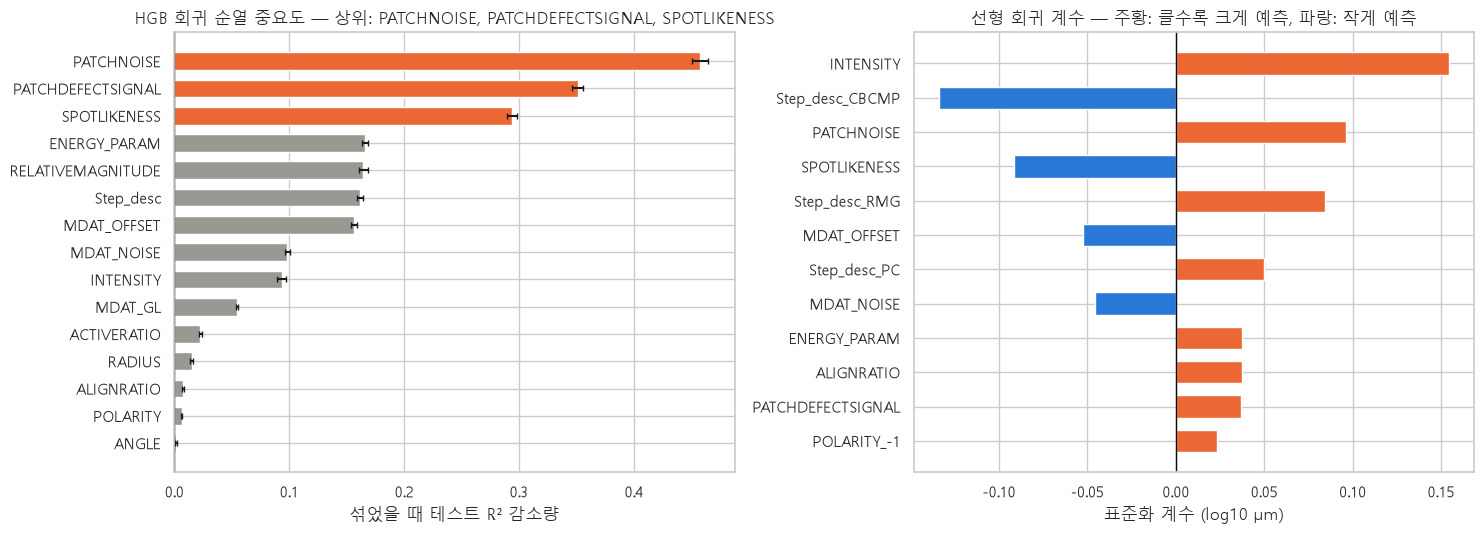

In [38]:
pi_r = permutation_importance(best_reg, Xr_te, yr_te, scoring="r2", n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_reg = pd.DataFrame({"평균": pi_r.importances_mean, "표준편차": pi_r.importances_std},
                        index=Xr_te.columns).sort_values("평균")
linr = final_reg["선형 회귀"]
coef_reg = pd.Series(linr.named_steps["model"].coef_, index=linr.named_steps["prep"].get_feature_names_out())
top_c = coef_reg.reindex(coef_reg.abs().sort_values().index[-12:])

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh(perm_reg.index, perm_reg["평균"], xerr=perm_reg["표준편차"], capsize=2, height=0.65,
             color=[C_REAL if i >= len(perm_reg) - 3 else C_GRAY for i in range(len(perm_reg))])
axes[0].axvline(0, color=C_INK, lw=1); axes[0].set_xlabel("섞었을 때 테스트 R² 감소량")
axes[0].set_title(f"HGB 회귀 순열 중요도 — 상위: {', '.join(perm_reg.index[::-1][:3])}")
axes[1].barh(top_c.index, top_c.values, color=[C_REAL if v > 0 else C_FALSE for v in top_c.values], height=0.65)
axes[1].axvline(0, color=C_INK, lw=1); axes[1].set_xlabel("표준화 계수 (log10 µm)")
axes[1].set_title("선형 회귀 계수 — 주황: 클수록 크게 예측, 파랑: 작게 예측")
plt.tight_layout(); plt.show()

**프롬프트 P39**
```text
[맥락] best_reg, Xr_te, perm_reg가 있어.
[작업] 회귀 순열 중요도 상위 2개 수치형 변수의 PDP를 그려줘 (분류 PDP와 같은 형식).
- 3000행 표본, kind='both', subsample=80, percentiles=(0.02, 0.98), grid_resolution=40
- y축은 '예측 log10 SIZE_D'이고, 오른쪽 보조 눈금 대신 제목에 µm 환산 범위(10**최소~10**최대)를 적어줘.
```

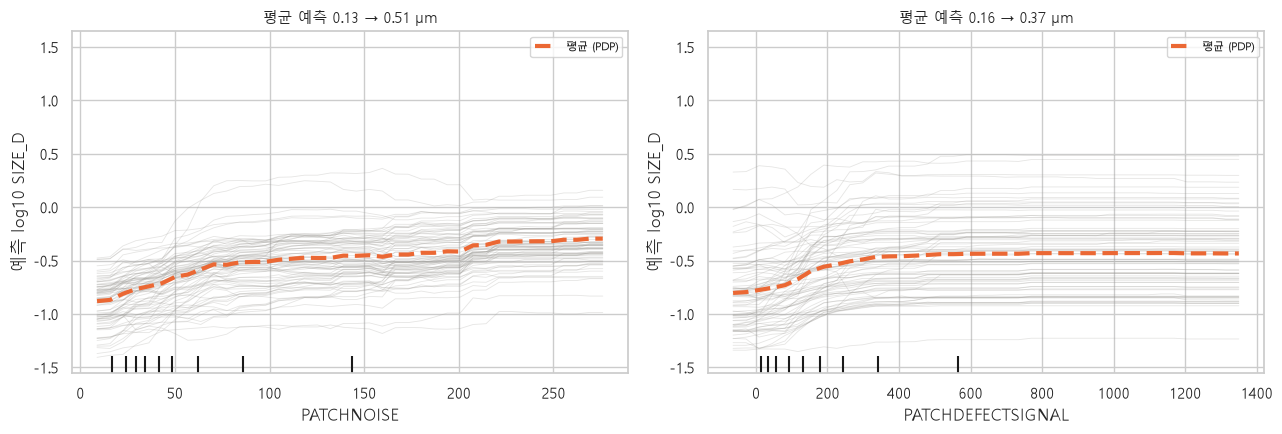

In [39]:
top_num_r = [c for c in perm_reg.sort_values("평균", ascending=False).index if c not in CAT_COLS][:2]
X_pdp_r = Xr_te.sample(3000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
disp = PartialDependenceDisplay.from_estimator(
    best_reg, X_pdp_r, top_num_r, kind="both", subsample=80, random_state=RANDOM_STATE,
    grid_resolution=40, percentiles=(0.02, 0.98), ax=axes,
    ice_lines_kw={"color": C_GRAY, "alpha": 0.25, "lw": 0.6},
    pd_line_kw={"color": C_REAL, "lw": 3, "label": "평균 (PDP)"})
for ax, pdr in zip(axes, disp.pd_results):
    avg = pdr["average"][0]
    ax.set_ylabel("예측 log10 SIZE_D"); ax.legend(loc="best", fontsize=8)
    ax.set_title(f"평균 예측 {10 ** avg.min():.2f} → {10 ** avg.max():.2f} µm", fontsize=11)
plt.tight_layout(); plt.show()

> **결과 해석**
> - **PATCHNOISE** 가 커질수록 예측 크기가 0.13 → 0.51µm로 **꾸준히 커집니다.** 결함이 클수록 주변 패치의 신호 변동도 커지는 것으로 해석할 수 있습니다.
> - **PATCHDEFECTSIGNAL** 은 약 300까지는 크기 예측이 빠르게 커지다가 그 뒤로 평평합니다(0.16 → 0.37µm). 신호가 **포화**되는 모양입니다.

**프롬프트 P40**
```text
[맥락] perm_clf(분류 순열 중요도), perm_reg(회귀 순열 중요도), group_of(변수→그룹 딕셔너리)가 있어.
[작업] 두 과제의 변수 중요도를 한 표로 요약해줘.
- 행: 모든 변수, 열: 그룹, 분류 순위, 분류 중요도(AUC 감소), 회귀 순위, 회귀 중요도(R² 감소)
- 회귀에서 쓰지 않은 변수(크기 변수)는 '—'로.
- 분류 순위 기준 정렬.
[출력] 표 + 두 과제의 공통 핵심 변수와 차이를 해석.
```

In [40]:
summary_imp = pd.DataFrame({"그룹": pd.Series(group_of),
                            "분류 중요도": perm_clf["평균"], "회귀 중요도": perm_reg["평균"]}).dropna(subset=["분류 중요도"])
summary_imp["분류 순위"] = summary_imp["분류 중요도"].rank(ascending=False).astype(int)
summary_imp["회귀 순위"] = summary_imp["회귀 중요도"].rank(ascending=False)
summary_imp = summary_imp.sort_values("분류 순위")
summary_imp["회귀 순위"] = summary_imp["회귀 순위"].map(lambda v: "—" if pd.isna(v) else int(v))
summary_imp["회귀 중요도"] = summary_imp["회귀 중요도"].map(lambda v: "—" if pd.isna(v) else f"{v:.4f}")
summary_imp[["그룹", "분류 순위", "분류 중요도", "회귀 순위", "회귀 중요도"]].round(4)

,그룹,분류 순위,분류 중요도,회귀 순위,회귀 중요도
MDAT_GL,신호,1,0.0440,10,0.0550
Step_desc,공정,2,0.0342,6,0.1616
MDAT_OFFSET,신호,3,0.0310,7,0.1564
SPOTLIKENESS,형상,4,0.0204,3,0.2936
RADIUS,위치,5,0.0197,12,0.0151
DEFECT_AREA,크기,6,0.0185,—,—
ACTIVERATIO,형상,7,0.0090,11,0.0228
MDAT_NOISE,신호,8,0.0068,8,0.0982
SIZE_D,크기,9,0.0057,—,—
INTENSITY,신호,10,0.0057,9,0.0935


> **결과 해석**
> - **두 과제의 핵심 변수가 다릅니다.** 분류(진짜냐 가짜냐)는 **MDAT_GL·MDAT_OFFSET 같은 배경·기준 신호**에 기대고, 회귀(얼마나 크냐)는 **PATCHNOISE·PATCHDEFECTSIGNAL 같은 결함 신호의 세기**에 기댑니다.
> - **SPOTLIKENESS(형상)** 와 **Step_desc(공정)** 는 두 과제 모두에서 상위권입니다. 공정마다 결함의 성격이 다르다는 EDA 결과와 같습니다.
> - 위치(RADIUS, ANGLE)는 두 과제 모두에서 영향이 작습니다. 특히 **ANGLE은 최하위**입니다. EDA에서 각도별 차이가 작았던 것과 일치합니다.

---
# 8장. 모델 저장 · 종합 리포트 · 연습문제

> **이 장의 목표**
> - 학습한 모델을 저장하고 새 데이터에 적용한다.
> - 분석 결과를 비전공자도 이해할 수 있게 요약한다.
> - 스스로 프롬프트를 작성해 모델링을 반복한다.

**프롬프트 P41**
```text
[맥락] best_clf(분류 Pipeline), best_reg(회귀 Pipeline), THR, FEAT_CLF, FEAT_REG, Xc_te, Xr_te가 있어.
[작업]
1. joblib으로 두 모델과 임계값·특성 목록을 하나의 딕셔너리로 묶어 'wafer_models.joblib'에 저장.
2. 다시 불러와서 테스트 데이터 앞 8행에 적용해 결과 표를 만들어줘:
   REAL 확률, 판정(THR 기준 'REAL(리뷰)'/'FALSE(생략)'), 실제 IS_DEFECT, 예측 크기(µm), 실제 크기(µm).
[조건] Pipeline 안에 전처리가 들어 있으므로 원본 열 그대로 넣으면 된다는 점을 주석으로 설명해줘.
```

In [41]:
import joblib
bundle = {"clf": best_clf, "reg": best_reg, "threshold": THR, "feat_clf": FEAT_CLF, "feat_reg": FEAT_REG}
joblib.dump(bundle, "wafer_models.joblib")
print("저장 완료 : wafer_models.joblib")

# ── 불러와서 새 데이터처럼 적용 (Pipeline이 전처리까지 하므로 원본 열을 그대로 넣으면 됨) ──
m = joblib.load("wafer_models.joblib")
new = te.head(8)
prob = m["clf"].predict_proba(new[m["feat_clf"]])[:, 1]
pd.DataFrame({"REAL 확률": prob.round(3),
              "판정": np.where(prob >= m["threshold"], "REAL(리뷰)", "FALSE(생략)"),
              "실제": new["IS_DEFECT"].values,
              "예측 크기(µm)": (10 ** m["reg"].predict(new[m["feat_reg"]])).round(3),
              "실제 크기(µm)": new["SIZE_D"].values})

저장 완료 : wafer_models.joblib


,REAL 확률,판정,실제,예측 크기(µm),실제 크기(µm)
0,0.5870,REAL(리뷰),REAL,0.4460,0.5460
1,0.0150,FALSE(생략),FALSE,0.1750,0.1980
2,0.0150,FALSE(생략),FALSE,0.0720,0.0490
3,0.8690,REAL(리뷰),REAL,0.4690,0.6460
4,0.0030,FALSE(생략),FALSE,0.0620,0.0990
5,0.8860,REAL(리뷰),FALSE,0.2580,0.2480
6,0.1040,FALSE(생략),FALSE,0.2200,0.4470
7,0.8480,REAL(리뷰),REAL,0.2190,0.1980


---
## 8-1. 종합 리포트 — 비전공자용 요약

| 구분 | 분류: 진성/가성결함 판정 | 회귀: 결함 크기 추정 |
|---|---|---|
| **입력** | 크기·신호·형상·위치·공정 19개 변수 | 신호·형상·위치·공정 15개 변수 (크기 변수 제외) |
| **제외한 누수 변수** | `Class` (정답 코드) | `SIZE_X`, `SIZE_Y`, `DEFECT_AREA` (크기 계산 재료) |
| **검증 방식** | 로트 단위 분할 (테스트 92개 로트, 학습과 겹침 0) + GroupKFold 5겹 | 동일 |
| **최종 모델** | HistGradientBoosting (튜닝) | HistGradientBoosting (튜닝) |
| **기준 모델 대비** | AUC 0.50 → **0.953** | MAE 0.253 → **0.124µm (51%↓)** |
| **핵심 성능** | 임계값 0.22에서 **재현율 98.1%, 리뷰 35% 절감** | **R² 0.82, 상대오차 중앙값 17%**, 등급 일치 84% |
| **약점** | CBCMP·RMG 공정의 특이도 70~75%, Class 10·14 놓침 | 1µm 이상 대형 결함을 작게 예측 (31%가 '중'으로) |
| **핵심 변수** | MDAT_GL, Step_desc, MDAT_OFFSET, SPOTLIKENESS | PATCHNOISE, PATCHDEFECTSIGNAL, SPOTLIKENESS |

**한 문장 결론**
> 검사 장비의 신호만으로 **가성결함의 상당 부분을 리뷰 전에 걸러낼 수 있고(진성결함 98% 유지 시 리뷰 35% 절감)**, 결함 크기도 **절반은 ±17% 안으로** 추정할 수 있다. 다만 **CBCMP 공정과 대형 결함은 추가 개선이 필요**하다.

**다음 액션 제안**
1. 놓치는 진성결함 1.9%의 비용을 현장과 함께 산정해 **임계값 최종 결정**
2. CBCMP 공정 전용 모델 또는 공정별 임계값 검토
3. 대형 결함(≥1µm) 데이터 추가 확보 또는 대형 여부 전용 분류 모델
4. 새 로트에서 성능을 주기적으로 확인하는 **모니터링 체계** (EDA의 p 관리도 활용)

## 8-2. 개념 정리 체크리스트

| 개념 | 한 줄 정의 | 이 노트북 위치 |
|---|---|---|
| 데이터 누수 | 예측 시점에 모르는 정보가 학습에 섞임 | 2-2 (Class, 크기 변수), 3-1 (그룹), 5-4 (임계값) |
| 그룹 분할 | 같은 로트를 학습/테스트에 나누지 않음 | 3장 |
| Pipeline | 전처리 + 모델을 한 덩어리로, 교차검증 시 전처리 누수 방지 | 3-2 |
| 교차검증 | 학습 데이터를 k겹으로 돌려가며 검증 | 5장, 6장 |
| 기준 모델 | 아무것도 배우지 않은 모델 — 최소 비교 대상 | 4장, 5장, 6장 |
| ROC-AUC | 임계값 무관한 순위 능력 | 4-1, 5장 |
| 재현율 / 특이도 | 진성 놓치지 않기 / 가성 걸러내기 | 5-4 |
| MAE / RMSE / R² / MdAPE | 절대 / 큰 오차 강조 / 설명력 / 상대 오차 | 4-2, 6장 |
| 검증 곡선 · 학습 곡선 | 복잡도·데이터 양에 따른 과적합 진단 | 5-1 |
| 하이퍼파라미터 튜닝 | 교차검증으로 설정값 선택 | 5-2, 6장 |
| 순열 중요도 · PDP | 모델 무관 해석 — 얼마나 / 어느 방향으로 | 7장 |

## 8-3. 연습문제 — 직접 프롬프트를 써서 풀어보세요

| # | 주제 | 과제 |
|:---:|---|---|
| 1 | 지표 | 임계값을 재현율 99%로 바꿔 THR을 다시 구하고, 테스트에서 리뷰 절감률이 얼마나 줄어드는지 비교 |
| 2 | 모델 | 공정이 CBCMP인 데이터만으로 분류 모델을 학습·평가하고, 전체 모델의 CBCMP 성능과 비교 |
| 3 | 누수 | `Class`를 특성에 넣은 모델의 교차검증 AUC를 구하고, 왜 쓸 수 없는지 설명 |
| 4 | 회귀 | `RADIUS`, `ANGLE`(위치)를 빼고 회귀 모델을 다시 학습해 R² 변화를 확인 |
| 5 | 중요도 | 회귀 모델에 그룹 순열 중요도(`group_perm`을 R² 버전으로 수정)를 적용 |
| 6 | 튜닝 | 랜덤포레스트 분류기의 `n_estimators`, `max_depth`, `min_samples_leaf`를 RandomizedSearchCV로 튜닝해 HGB와 비교 |

**연습문제 1 — 재현율 99% 임계값 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[검증 방법]
[조건]
[출력]
```

In [42]:
# 연습문제 1 : AI가 만든 코드를 붙여넣고 실행하세요


**연습문제 2 — CBCMP 전용 모델 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[검증 방법]
[조건]
[출력]
```

In [43]:
# 연습문제 2 : AI가 만든 코드를 붙여넣고 실행하세요


**연습문제 3 — Class 누수 실험 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[검증 방법]
[조건]
[출력]
```

In [44]:
# 연습문제 3 : AI가 만든 코드를 붙여넣고 실행하세요


**연습문제 4 — 위치 변수 제거 회귀 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[검증 방법]
[조건]
[출력]
```

In [45]:
# 연습문제 4 : AI가 만든 코드를 붙여넣고 실행하세요


**연습문제 5 — 회귀 그룹 중요도 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[검증 방법]
[조건]
[출력]
```

In [46]:
# 연습문제 5 : AI가 만든 코드를 붙여넣고 실행하세요


**연습문제 6 — 랜덤포레스트 튜닝 : 나의 프롬프트**
```text
(여기에 프롬프트를 작성하세요)
[맥락]
[작업]
[검증 방법]
[조건]
[출력]
```

In [47]:
# 연습문제 6 : AI가 만든 코드를 붙여넣고 실행하세요


---
<details>
<summary><b>연습문제 예시 프롬프트 & 답안 (클릭하여 펼치기)</b></summary>

**1. 예시 프롬프트** : "학습 OOF 확률 `oof`와 `yc_tr`로 재현율 0.99 이상인 가장 큰 임계값 THR99를 구하고, 테스트 확률 `p_best`에 THR과 THR99를 적용해 리뷰 생략 비율과 놓친 진성결함 수를 표로 비교해줘. 테스트로 임계값을 정하지 마."
```python
THR99 = thr_tbl.loc[thr_tbl["재현율"] >= 0.99, "임계값"].max()
pd.DataFrame({t: {"리뷰 생략 비율": (p_best < t).mean(),
                  "놓친 진성결함": ((p_best < t) & (yc_te.values == 1)).sum()} for t in [THR, THR99]})
```

**2.**
```python
m_tr, m_te = Xc_tr["Step_desc"] == "CBCMP", Xc_te["Step_desc"] == "CBCMP"
cb = clf_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)).fit(Xc_tr[m_tr], yc_tr[m_tr])
print("CBCMP 전용:", roc_auc_score(yc_te[m_te], cb.predict_proba(Xc_te[m_te])[:, 1]))
print("전체 모델 :", roc_auc_score(yc_te[m_te], p_best[m_te.values]))
```

**3.**
```python
CAT_COLS = ["Step_desc", "POLARITY", "Class"]        # Class를 범주형으로 추가 (실험용)
leaky = clf_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE), features=FEAT_CLF + ["Class"])
print(cross_validate(leaky, tr[FEAT_CLF + ["Class"]], yc_tr, cv=gkf, groups=g_tr, scoring="roc_auc")["test_score"].mean())
CAT_COLS = ["Step_desc", "POLARITY"]                 # 원래대로 되돌리기
```

**4.**
```python
f4 = [c for c in FEAT_REG if c not in POS_COLS]
print(cross_validate(reg_pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE), features=f4),
                     Xr_tr[f4], yr_tr, cv=gkf, groups=g_tr, scoring="r2")["test_score"].mean())
```

**5.** `group_perm` 안의 `roc_auc_score(y, model.predict_proba(X)[:, 1])`를 `r2_score(y, model.predict(X))`로 바꾸고, 그룹에서 "크기"를 뺀 뒤 `best_reg`, `Xr_te`, `yr_te`로 실행

**6.**
```python
rf_search = RandomizedSearchCV(clf_pipe(RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE)),
    {"model__n_estimators": [100, 200, 400], "model__max_depth": [None, 10, 20],
     "model__min_samples_leaf": [1, 2, 5, 10]}, n_iter=8, cv=gkf, scoring="roc_auc", random_state=RANDOM_STATE)
rf_search.fit(Xc_tr, yc_tr, groups=g_tr); print(rf_search.best_params_, rf_search.best_score_)
```
</details>

---
### 수고하셨습니다!
**다음 단계** : 모델 모니터링(새 로트에서 성능이 유지되는지) → 확률 보정(Calibration) → 비용 기반 임계값 최적화